<a href="https://colab.research.google.com/github/willianfurtado/rbf/blob/main/rbf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementação de uma Rede RBF para classificação binária

#Base de Dados

In [ ]:
from google.colab import drive
from google.colab import files
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# drive.mount('/content/drive')


# Parte A - Exploração dos dados

## Leitura do dataset

In [ ]:
upload = files.upload()

df = pd.read_csv('rbf_exercicio_2_duas_luas.csv', dtype=str)

df.head()

Saving rbf_exercicio_2_duas_luas.csv to rbf_exercicio_2_duas_luas.csv


,x1,x2,classe,split
0,9.206.877.524.842.100,2.405.712.835.382.740,0,test
1,8.101.450.948.997.110,16.066.012.328.868.000,0,train
2,10.629.404.923.393.200,12.951.783.812.160.800,0,test
3,9.668.052.287.218.050,9.359.490.889.154.470,0,train
4,9.696.796.233.426.940,6.164.722.577.580.160,0,test


## Processo de padronização dos dados

In [ ]:
def parse_num(s):
    s = str(s).strip()
    neg = s.startswith('-')
    digits = s.lstrip('-').replace('.', '')
    return (-1 if neg else 1) * int(digits) / 10 ** len(digits)

## Separação de treino e teste

In [ ]:
df['x1'] = df['x1'].apply(parse_num)
df['x2'] = df['x2'].apply(parse_num)
df['classe'] = df['classe'].astype(int)

df_train = df[df['split'] == 'train'].reset_index(drop=True)
df_test  = df[df['split'] == 'test'].reset_index(drop=True)

print(df_train.shape, df_test.shape)   # (210, 4) (90, 4)
df.head()

(210, 4) (90, 4)


,x1,x2,classe,split
0,0.920688,0.240571,0,test
1,0.810145,0.160660,0,train
2,0.106294,0.129518,0,test
3,0.966805,0.935949,0,train
4,0.969680,0.616472,0,test


## Gráfico com os pontos do treinamento

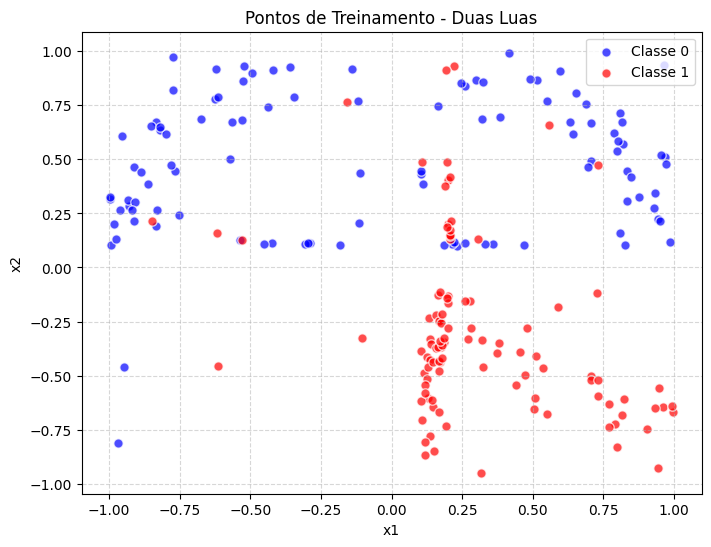

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
for c, cor in [(0, 'blue'), (1, 'red')]:
    d = df_train[df_train['classe'] == c]
    plt.scatter(d['x1'], d['x2'], color=cor, label=f'Classe {c}',
                alpha=0.7, edgecolors='white', s=45)

plt.title('Pontos de Treinamento - Duas Luas')
plt.xlabel('x1'); plt.ylabel('x2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Gráfico com as duas classes

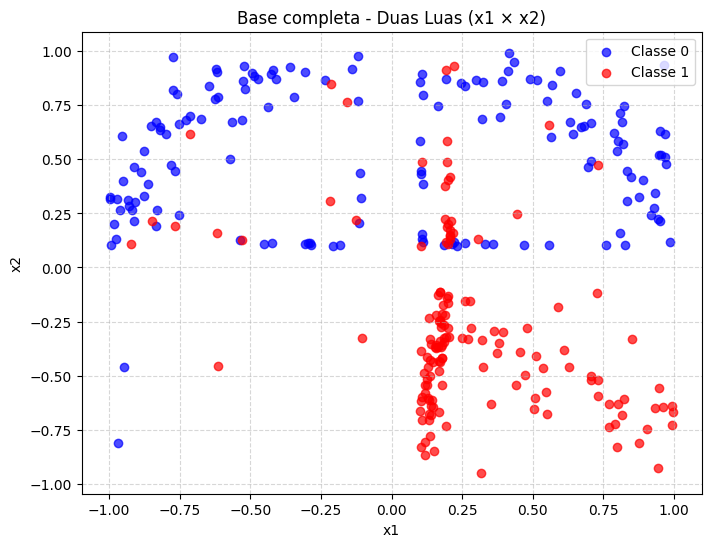

In [ ]:
plt.figure(figsize=(8, 6))
for c, cor in [(0, 'blue'), (1, 'red')]:
    d = df[df['classe'] == c]
    plt.scatter(d['x1'], d['x2'], color=cor, label=f'Classe {c}', alpha=0.7)

plt.title('Base completa - Duas Luas (x1 × x2)')
plt.xlabel('x1'); plt.ylabel('x2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Treino e teste com símbolos diferentes

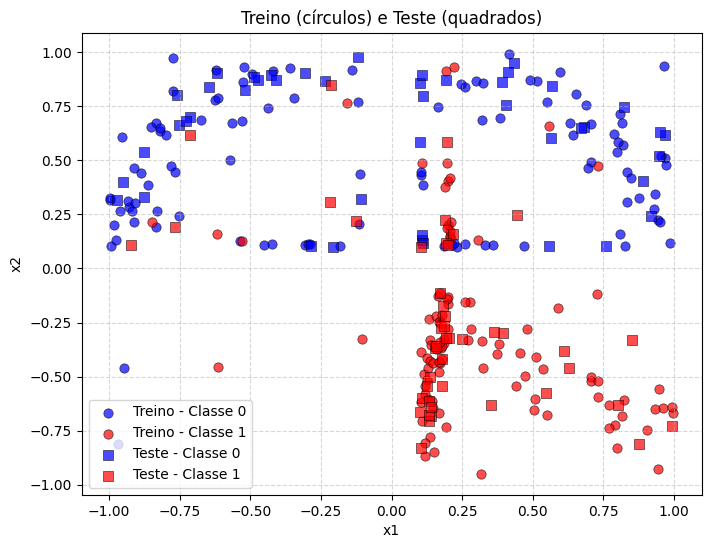

In [ ]:
plt.figure(figsize=(8, 6))
estilos = {('train', 0): ('blue', 'o', 'Treino - Classe 0'),
           ('train', 1): ('red',  'o', 'Treino - Classe 1'),
           ('test',  0): ('blue', 's', 'Teste - Classe 0'),
           ('test',  1): ('red',  's', 'Teste - Classe 1')}

for (conjunto, c), (cor, marcador, rotulo) in estilos.items():
    d = df[(df['split'] == conjunto) & (df['classe'] == c)]
    plt.scatter(d['x1'], d['x2'], color=cor, marker=marcador, s=45,
                alpha=0.7, edgecolors='black', linewidths=0.5, label=rotulo)

plt.title('Treino (círculos) e Teste (quadrados)')
plt.xlabel('x1'); plt.ylabel('x2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Quantidade de amostras por classe

In [ ]:
print('Total por classe:')
print(df['classe'].value_counts().sort_index(), '\n')

print('Por conjunto e classe:')
print(pd.crosstab(df['split'], df['classe'], margins=True,
                  rownames=['Conjunto'], colnames=['Classe']))

Total por classe:
classe
0    150
1    150
Name: count, dtype: int64 

Por conjunto e classe:
Classe      0    1  All
Conjunto               
test       45   45   90
train     105  105  210
All       150  150  300


## *Pergunta* - Onde estão as regiões de maior dificuldade de classificação?

Nas regiões de fronteira direta entre as classes 0 e 1, observando-se pontos vermelhos subindo para a área dos pontos azuis.

# Implementação do K-Means

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def initialize_centers(X, k, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=k, replace=False)
    return X[idx].copy()

def assign_clusters(X, centers):
    d = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
    return np.argmin(d, axis=1)

def plot_step(X, centers, labels, title):
    plt.figure(figsize=(7, 5))
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', alpha=0.6, s=40)
    plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200,
                edgecolors='black', linewidths=2, label='Centros')
    plt.title(title)
    plt.xlabel('x1'); plt.ylabel('x2')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

def kmeans(X, k, seed=None, max_iter=100, tol=1e-6, plot_iterations=True):
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    centers = initialize_centers(X, k, seed)

    for iteration in range(1, max_iter + 1):
        labels = assign_clusters(X, centers)

        if plot_iterations:
            plot_step(X, centers, labels, f'K-means — Iteração {iteration}')

        new_centers = centers.copy()
        for j in range(k):
            members = X[labels == j]
            if len(members) > 0:
                new_centers[j] = members.mean(axis=0)
            else:
                new_centers[j] = X[rng.integers(len(X))]

        if np.allclose(centers, new_centers, atol=tol):
            print(f'K-means convergiu na iteração {iteration}!')
            centers = new_centers
            break
        centers = new_centers

    labels = assign_clusters(X, centers)
    return centers, labels

In [ ]:
def train_rbf(X, y, k, sigma, seed):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    centers, _ = kmeans(X, k, seed)
    Phi = rbf_features(X, centers, sigma)
    t = np.where(y == 1, 1.0, -1.0)          # classe 0 -> -1, classe 1 -> +1
    w = np.linalg.pinv(Phi) @ t               # w = Φ⁺ t
    return {'centers': centers, 'sigma': sigma, 'w': w}


def predict_rbf(X, model):
    Phi = rbf_features(X, model['centers'], model['sigma'])
    y_hat = Phi @ model['w']
    return (y_hat >= 0).astype(int), y_hat

## Atribuição ao centro mais próximo

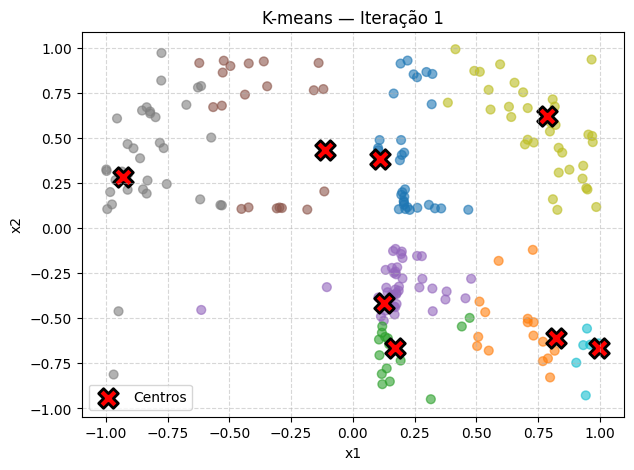

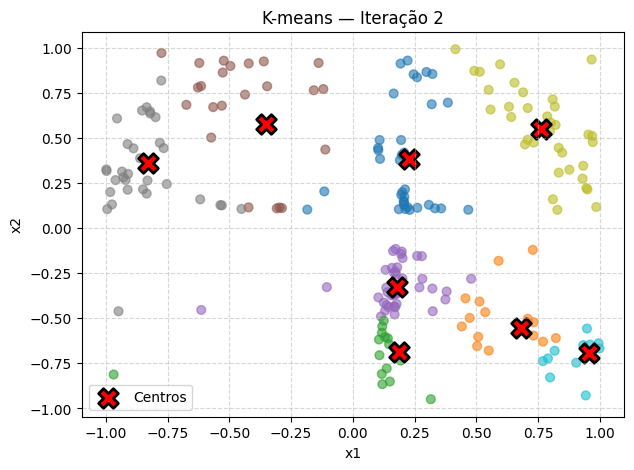

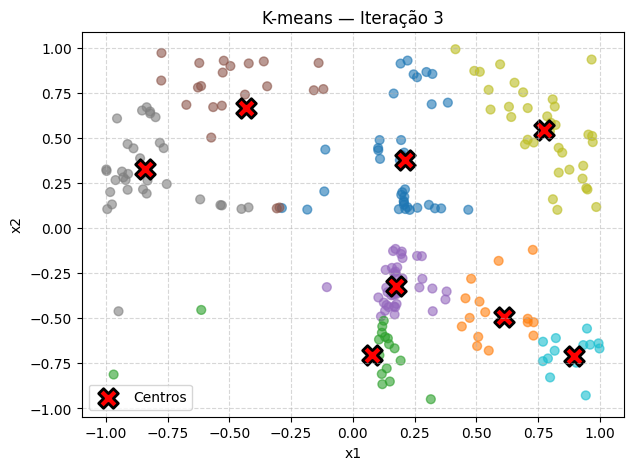

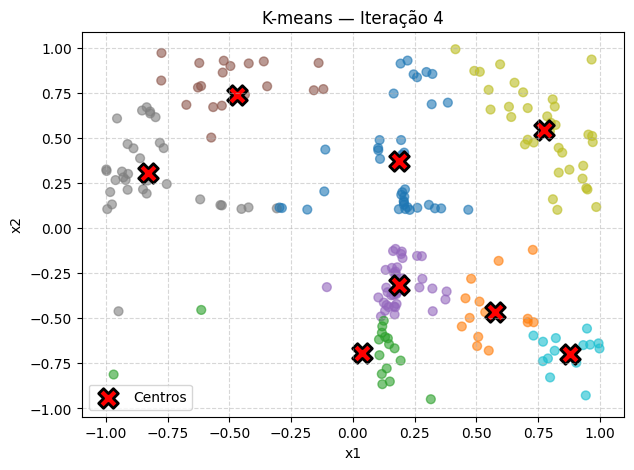

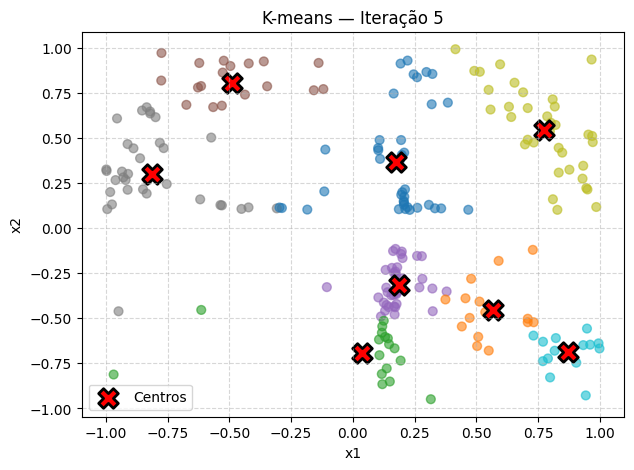

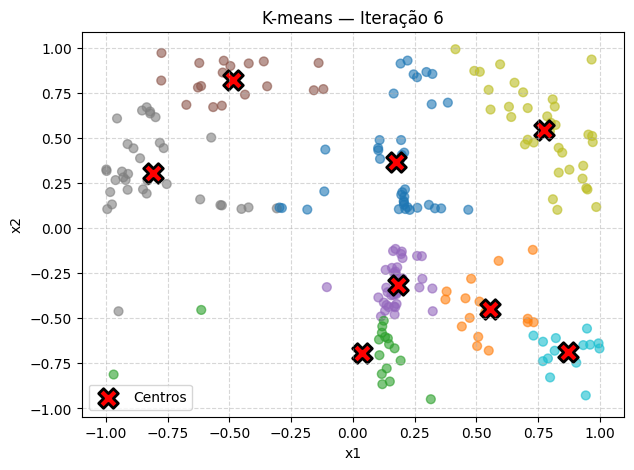

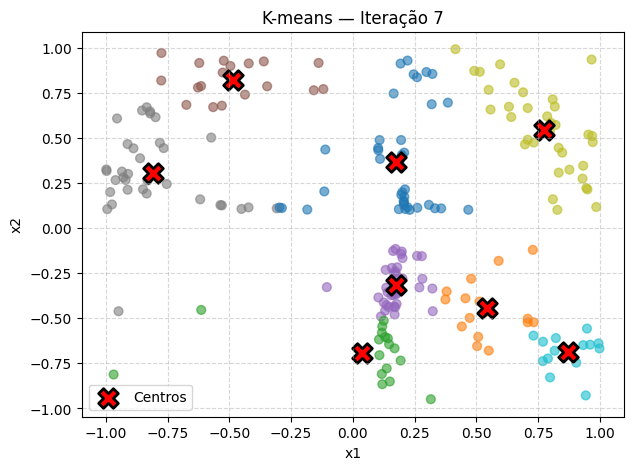

K-means convergiu na iteração 7!


In [ ]:
X_train = df_train[['x1', 'x2']].values
centers, labels = kmeans(X_train, k=8, seed=42)

## Perguntas

### 1 - Os centros convergiram?
R = Sim

### 2 - Quantas iterações foram necessárias?
R = 7

### 3 - A inicialização altera o resultado?
R = A inicialização tende a alterar o resultado. Isso se dá pela característica de aleatoriedade das sementes e também da posição a qual os centros iniciais irão cair.



### 4 -  Execute o K-means com três sementes diferentes e compare os centros.

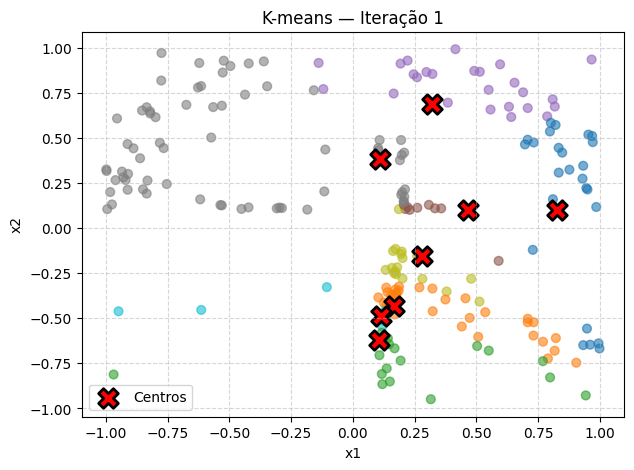

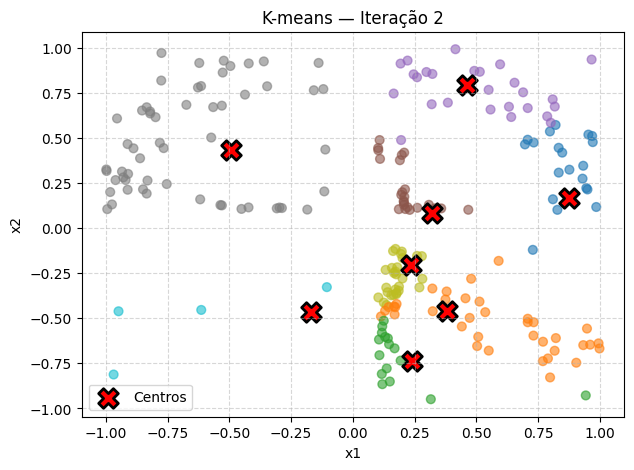

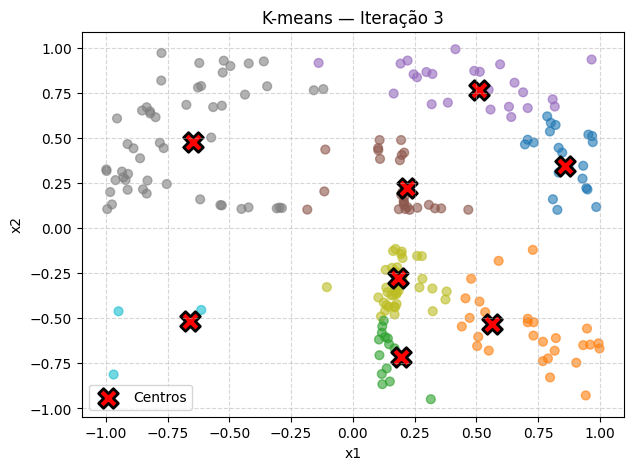

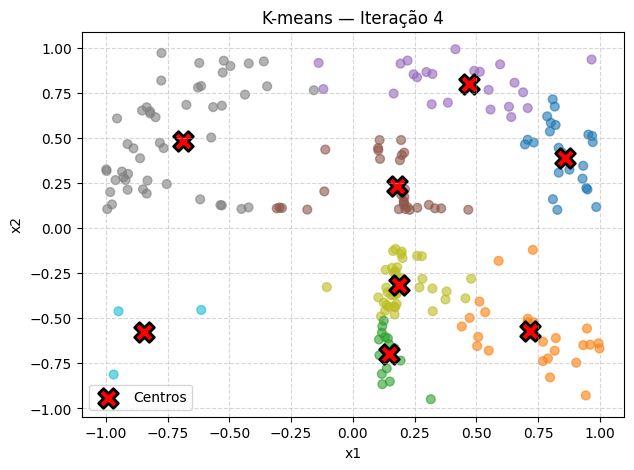

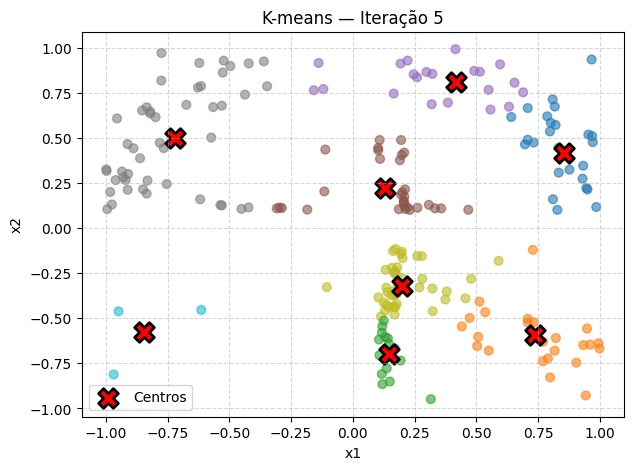

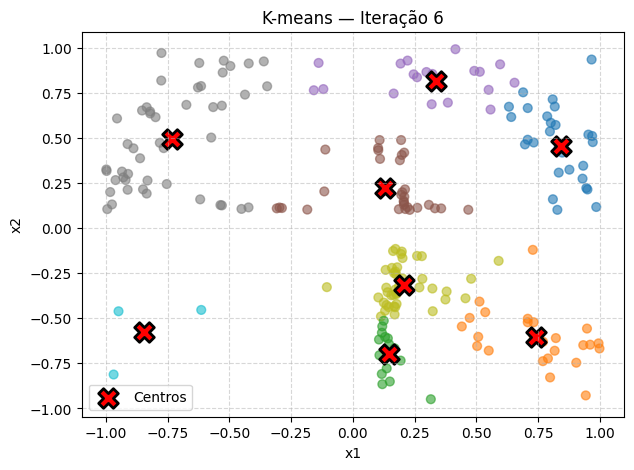

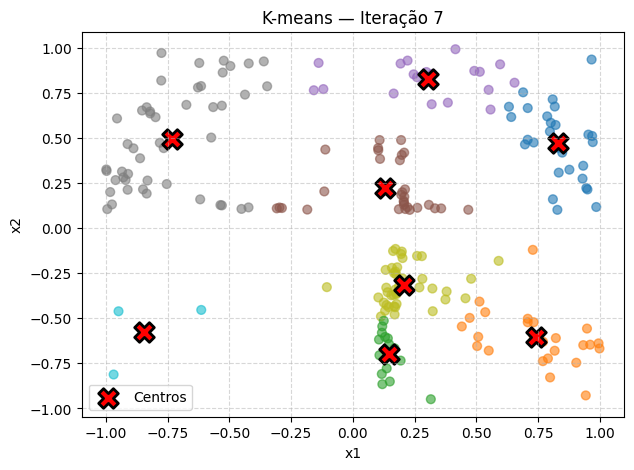

K-means convergiu na iteração 7!


In [ ]:
centers, labels = kmeans(X_train, k=8, seed=3)

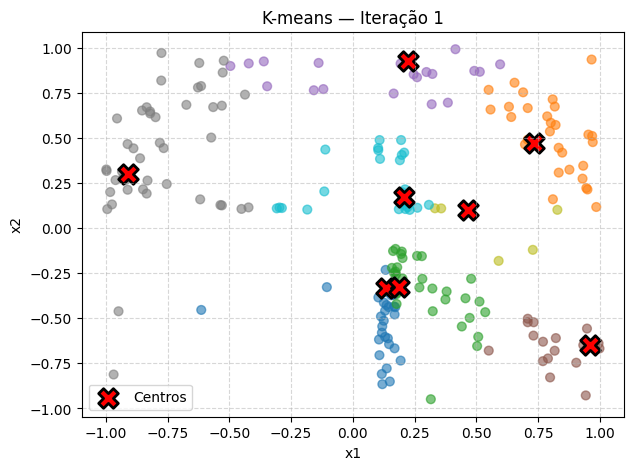

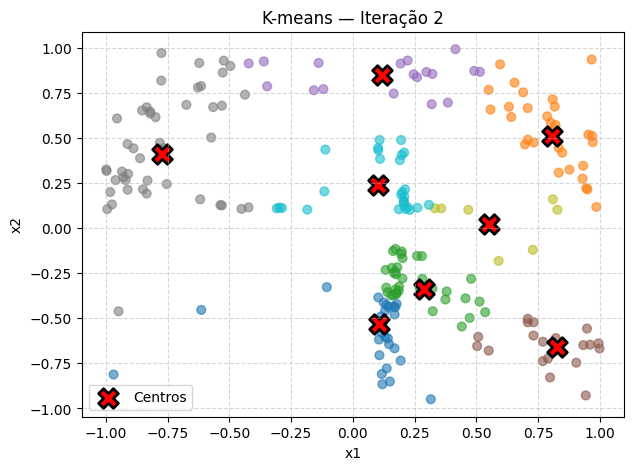

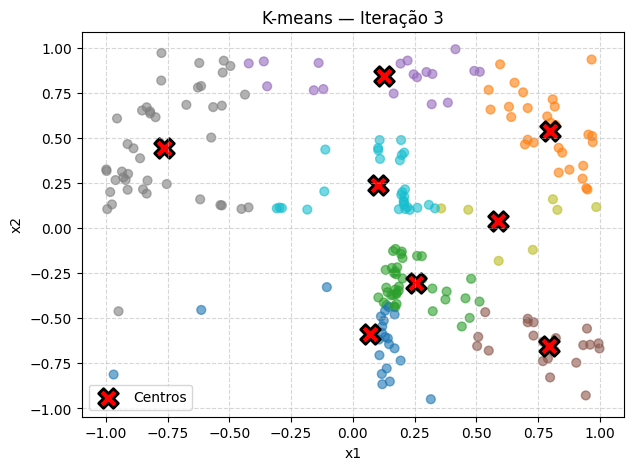

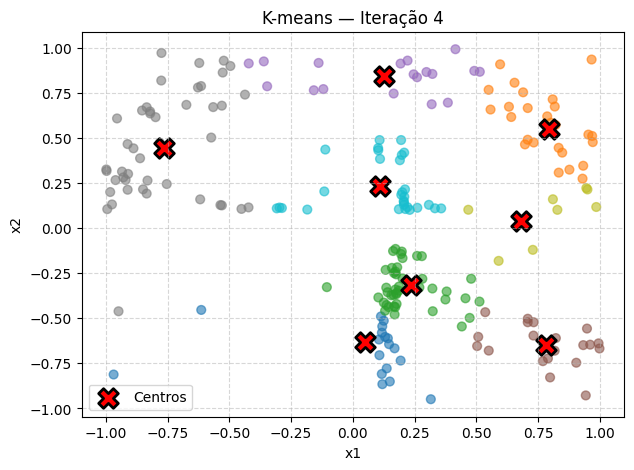

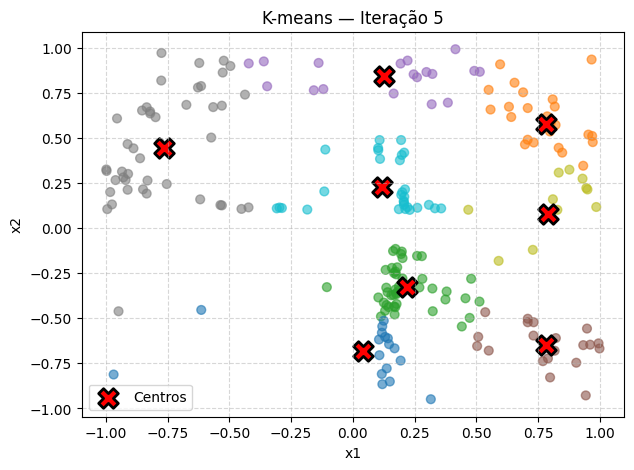

...

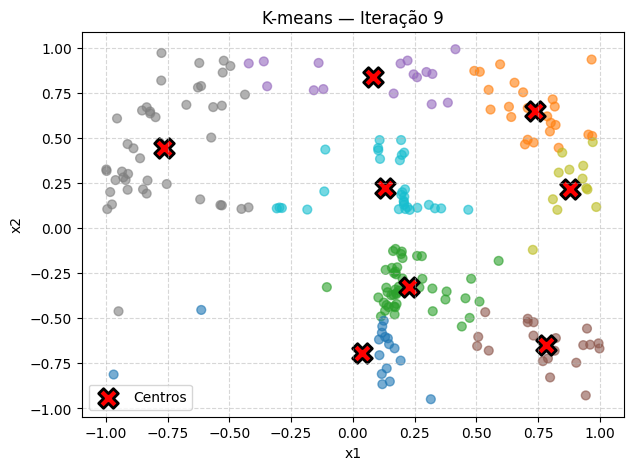

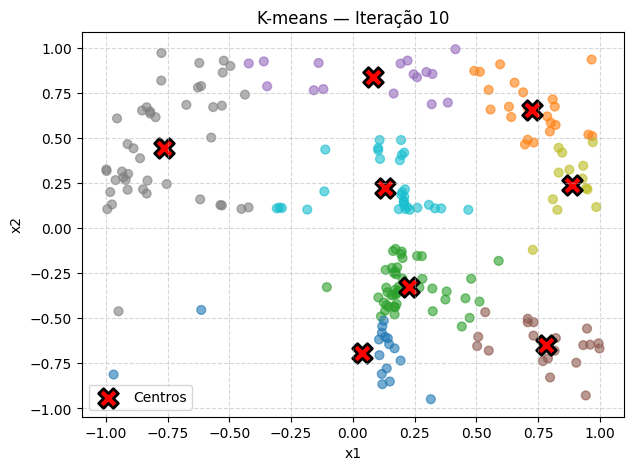

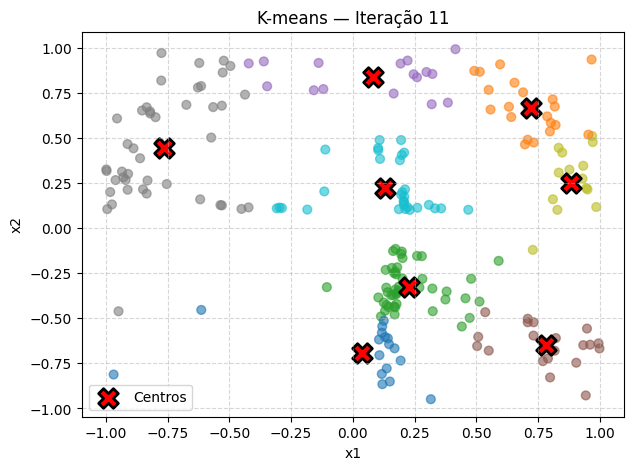

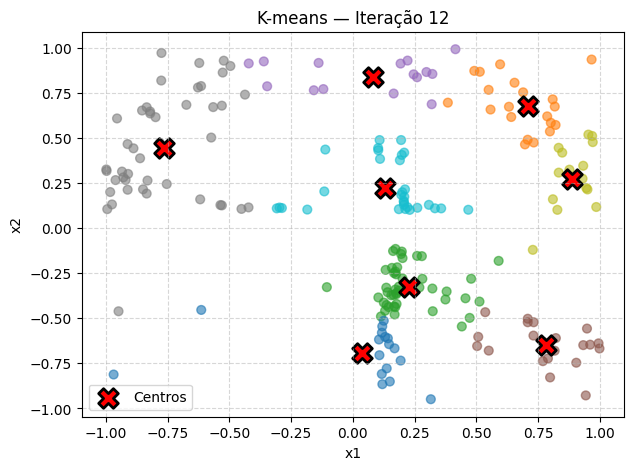

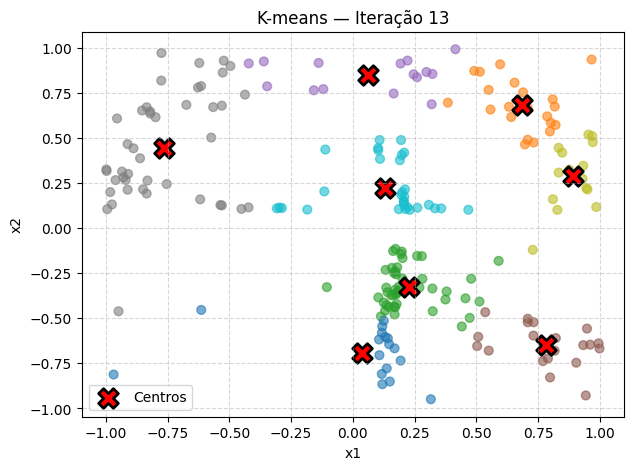

K-means convergiu na iteração 13!


In [ ]:
centers, labels = kmeans(X_train, k=8, seed=99)

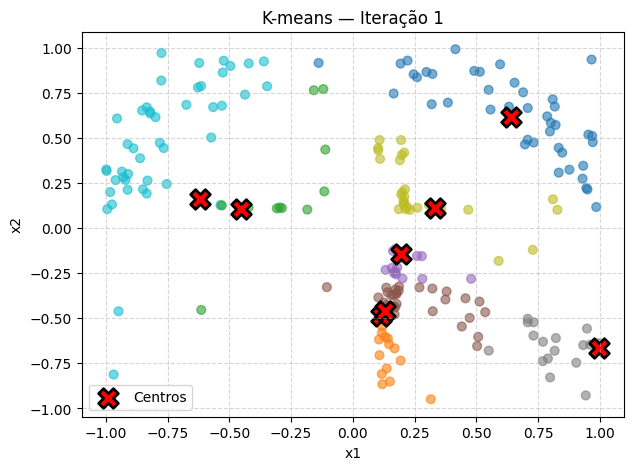

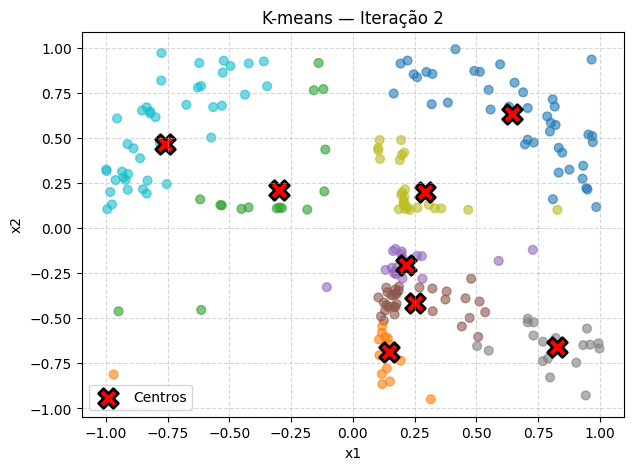

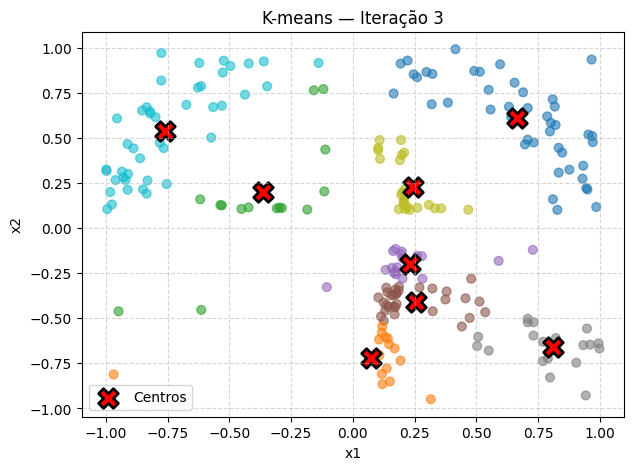

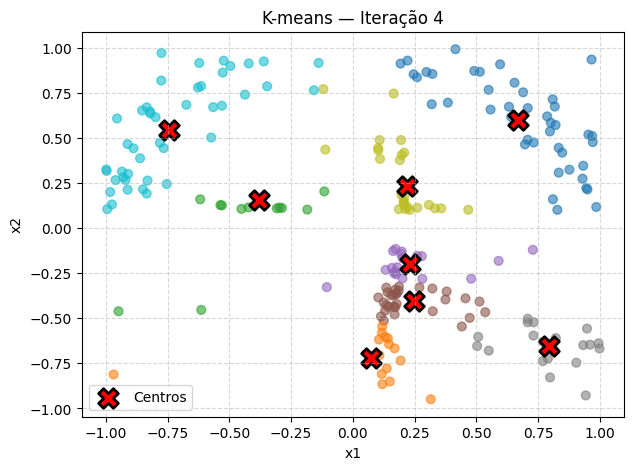

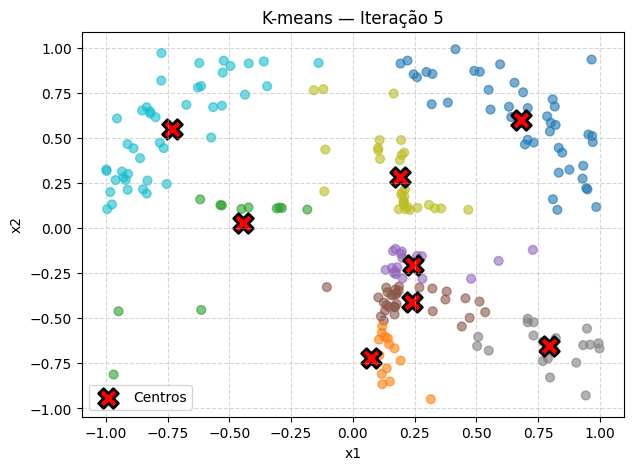

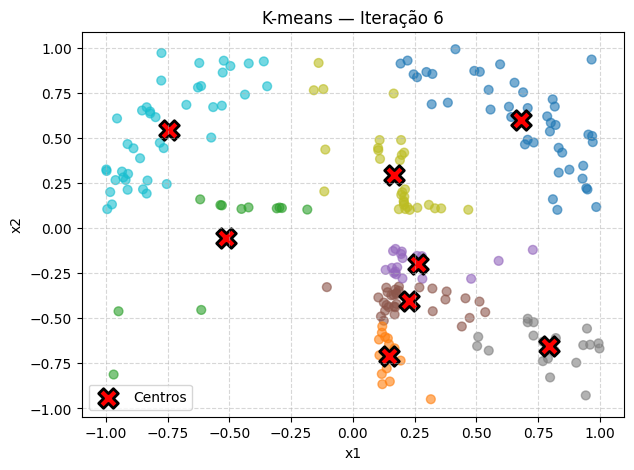

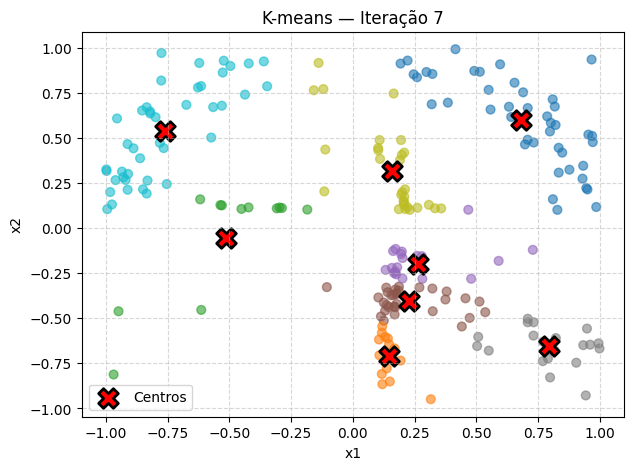

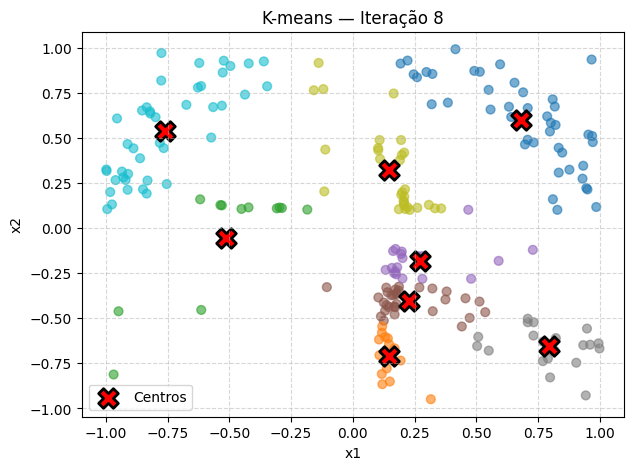

K-means convergiu na iteração 8!


In [ ]:
centers, labels = kmeans(X_train, k=8, seed=10)

#### Comparação
Seed=3  -> 7  iterações
Seed=99 -> 13 iterações
Seed=10 -> 8  iterações

# Parte C - Função de ativação RBF

## Função de ativação

In [ ]:
def rbf_activation(X, C, sigma=0.35):
    X = np.asarray(X, dtype=float)
    C = np.asarray(C, dtype=float)
    sq_dist = np.sum((X[:, None, :] - C[None, :, :]) ** 2, axis=2)
    return np.exp(-sq_dist / (2 * sigma ** 2))

def rbf_features(X, centers, sigma):
    """Matriz de projeto, shape (N, K+1), com bias na primeira coluna."""
    phi = rbf_activation(X, centers, sigma)
    return np.hstack([np.ones((phi.shape[0], 1)), phi])

## Centros (K=8) e matriz Φ

In [ ]:
X_train = df_train[['x1', 'x2']].values
centers, labels = kmeans(X_train, k=8, seed=42, plot_iterations=False)

sigma = 0.35
Phi = rbf_features(X_train, centers, sigma)
print(Phi.shape)            # (210, 8)
print(Phi.min(), Phi.max())

K-means convergiu na iteração 7!
(210, 9)
2.0712684670765207e-10 1.0


## Visualização 1 - mapa de calor da ativação de um centro

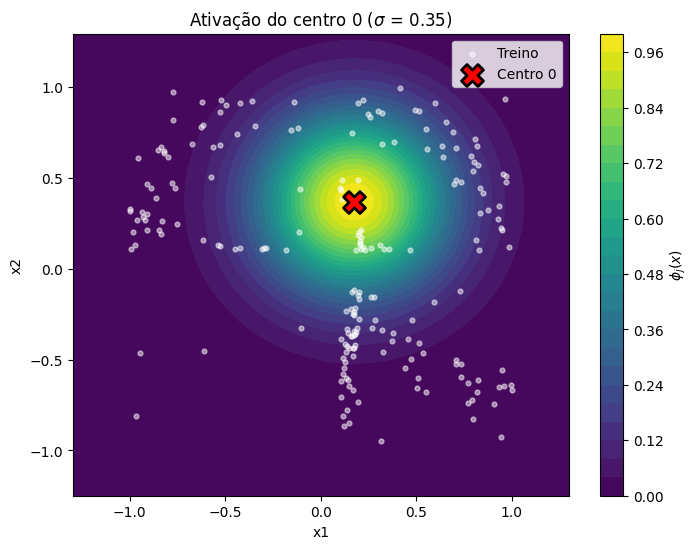

In [ ]:
import matplotlib.pyplot as plt

j = 0  # índice do centro escolhido
margem = 0.3
x_min, x_max = X_train[:, 0].min() - margem, X_train[:, 0].max() + margem
y_min, y_max = X_train[:, 1].min() - margem, X_train[:, 1].max() + margem

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grade = np.c_[xx.ravel(), yy.ravel()]

zz = rbf_activation(grade, centers[j:j+1], sigma).reshape(xx.shape)

plt.figure(figsize=(8, 6))
hm = plt.contourf(xx, yy, zz, levels=30, cmap='viridis')
plt.colorbar(hm, label=r'$\phi_j(x)$')
plt.scatter(X_train[:, 0], X_train[:, 1], c='white', s=12, alpha=0.5, label='Treino')
plt.scatter(*centers[j], c='red', marker='X', s=250, edgecolors='black',
            linewidths=2, label=f'Centro {j}')
plt.title(rf'Ativação do centro {j} ($\sigma$ = {sigma})')
plt.xlabel('x1'); plt.ylabel('x2')
plt.legend()
plt.show()

##

## Visualização 2: dados com os centros

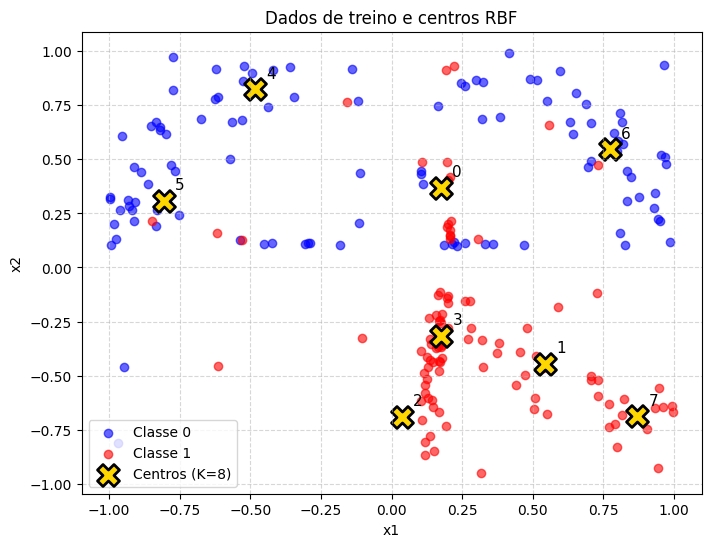

In [ ]:
plt.figure(figsize=(8, 6))
for c, cor in [(0, 'blue'), (1, 'red')]:
    d = df_train[df_train['classe'] == c]
    plt.scatter(d['x1'], d['x2'], color=cor, alpha=0.6, label=f'Classe {c}')

plt.scatter(centers[:, 0], centers[:, 1], c='gold', marker='X', s=250,
            edgecolors='black', linewidths=2, label='Centros (K=8)')
for i, (cx, cy) in enumerate(centers):
    plt.annotate(str(i), (cx, cy), textcoords='offset points', xytext=(8, 8), fontsize=11)

plt.title('Dados de treino e centros RBF')
plt.xlabel('x1'); plt.ylabel('x2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Parte D - Construção da matriz de projeto

In [ ]:
X_train = df_train[['x1', 'x2']].values
y_train = df_train['classe'].values
k, sigma, seed = 8, 0.35, 42

centers, _ = kmeans(X_train, k, seed, plot_iterations=False)
Phi = rbf_features(X_train, centers, sigma)

print('Phi.shape:', Phi.shape)                 # (210, 9)
print('Cinco primeiras linhas:\n', np.round(Phi[:5], 4))
print('Máximo das ativações:', Phi[:, 1:].max())
print('Mínimo das ativações:', Phi[:, 1:].min())

K-means convergiu na iteração 7!
Phi.shape: (210, 9)
Cinco primeiras linhas:
 [[1.000e+00 1.616e-01 1.673e-01 4.500e-03 7.700e-02 2.000e-04 0.000e+00
  5.425e-01 5.200e-02]
 [1.000e+00 2.080e-02 2.000e-04 0.000e+00 1.000e-04 2.000e-04 0.000e+00
  4.612e-01 0.000e+00]
 [1.000e+00 5.300e-02 1.235e-01 1.800e-03 3.210e-02 0.000e+00 0.000e+00
  3.933e-01 6.680e-02]
 [1.000e+00 8.130e-02 8.370e-02 1.100e-03 2.750e-02 1.000e-04 0.000e+00
  5.783e-01 3.300e-02]
 [1.000e+00 7.020e-02 1.140e-02 1.000e-04 4.700e-03 1.000e-04 0.000e+00
  8.510e-01 2.700e-03]]
Máximo das ativações: 0.9991626585762816
Mínimo das ativações: 2.0712684670765207e-10


## Por que a matriz de projeto possui K + 1 colunas?
Porque cada linha precisa de K ativações mais 1 coluna de bias.

# Parte E - Treinamento

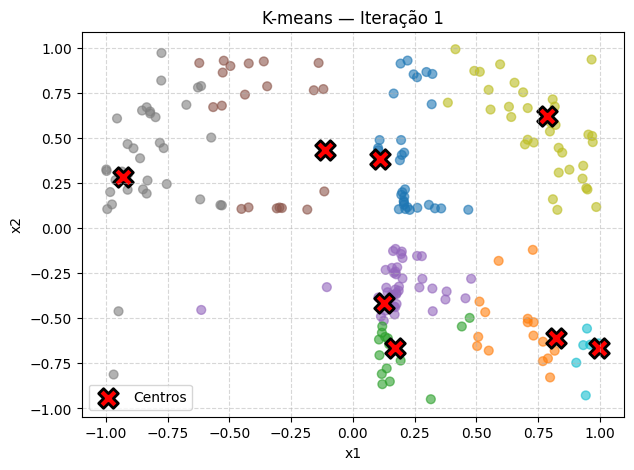

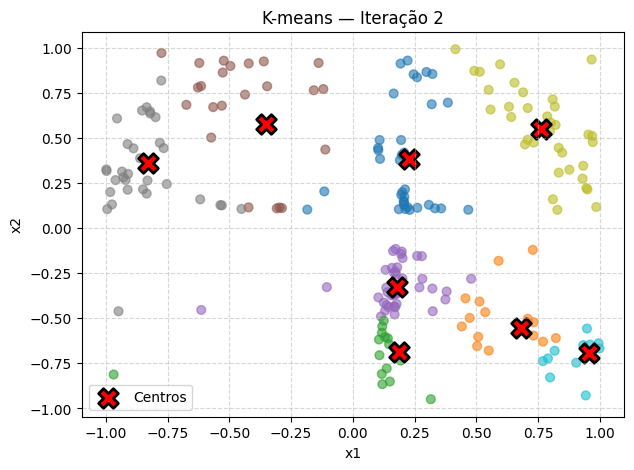

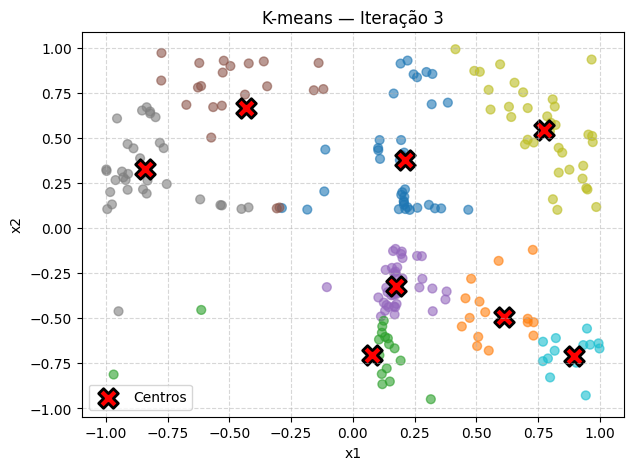

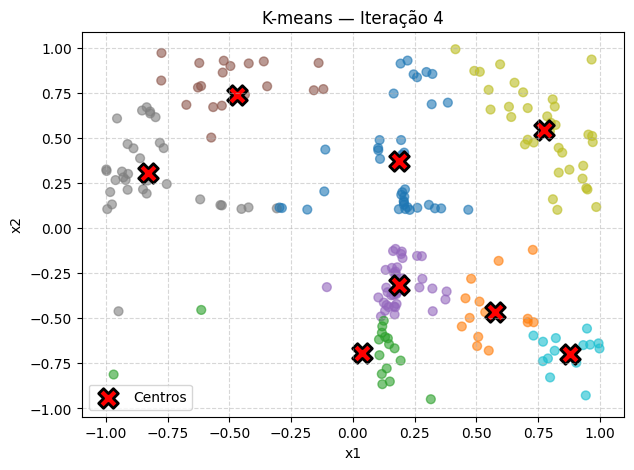

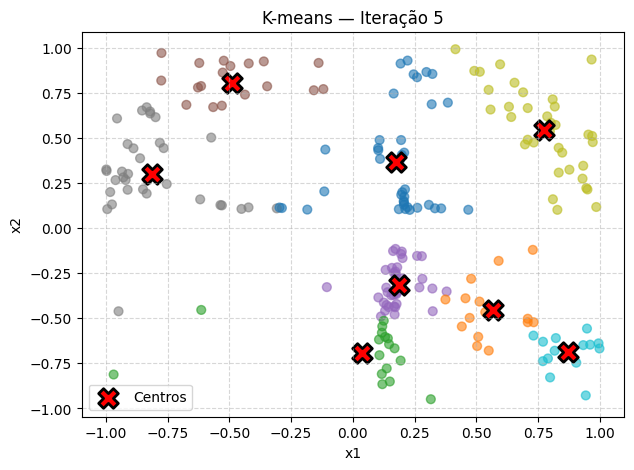

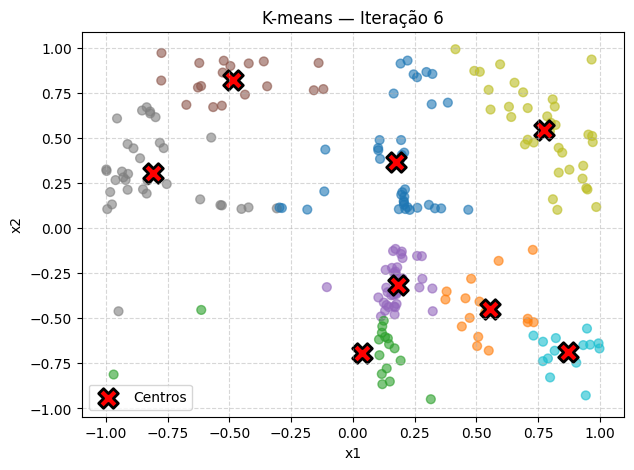

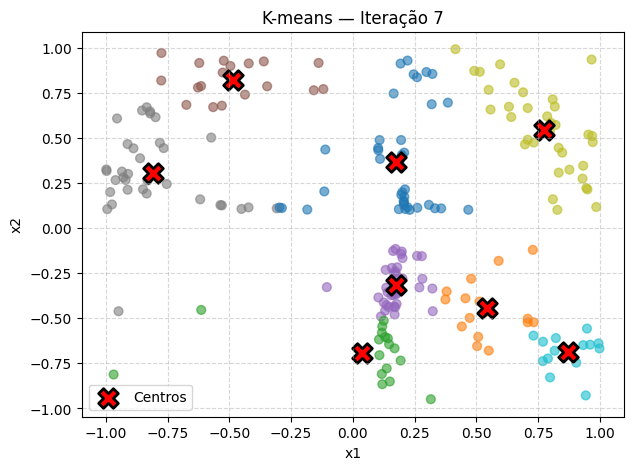

K-means convergiu na iteração 7!
Pesos w: [-0.708  0.734  0.175  1.159  0.742 -0.32  -0.109 -0.399  1.574]
Acurácia treino: 0.905
Acurácia teste:  0.878


In [ ]:
model = train_rbf(X_train, y_train, k=8, sigma=0.35, seed=42)

# Treino
c_train, y_hat_train = predict_rbf(X_train, model)
acc_train = np.mean(c_train == y_train)

# Teste
X_test = df_test[['x1', 'x2']].values
y_test = df_test['classe'].values
c_test, _ = predict_rbf(X_test, model)
acc_test = np.mean(c_test == y_test)

print('Pesos w:', np.round(model['w'], 3))
print(f'Acurácia treino: {acc_train:.3f}')
print(f'Acurácia teste:  {acc_test:.3f}')

## Parte F - Avaliação

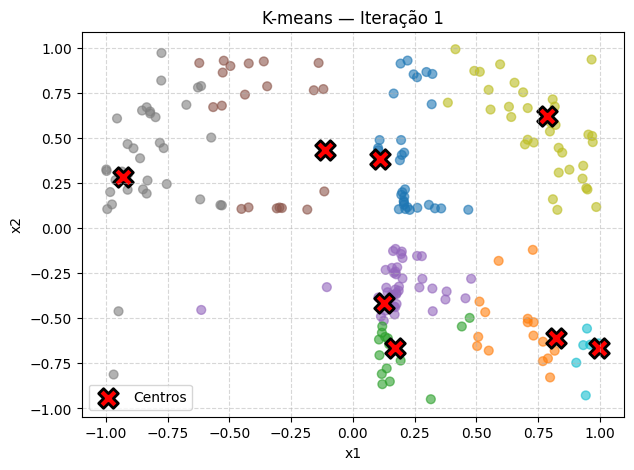

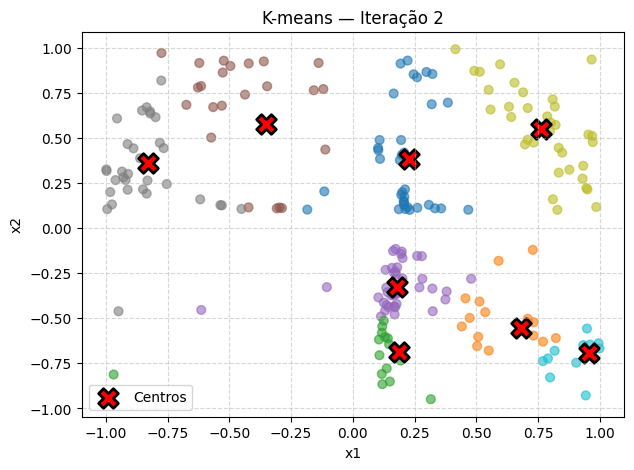

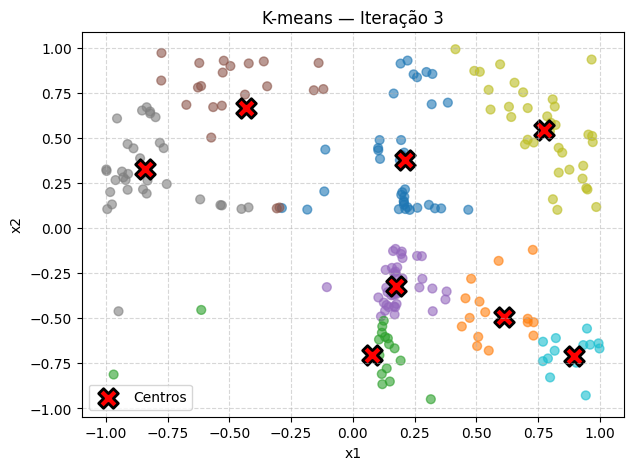

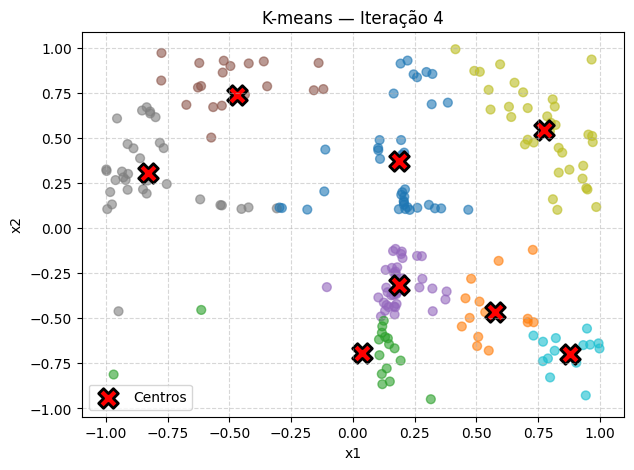

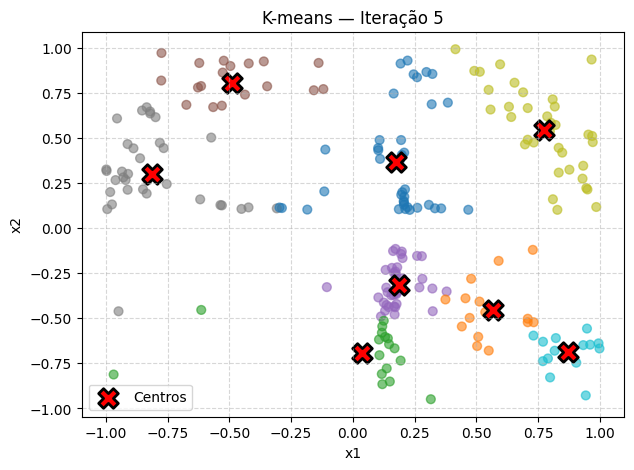

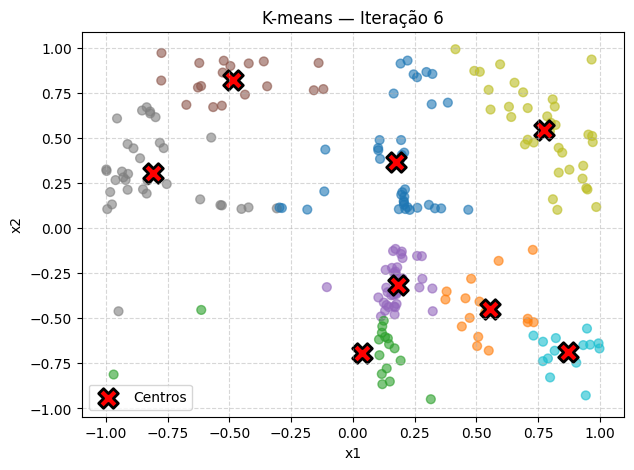

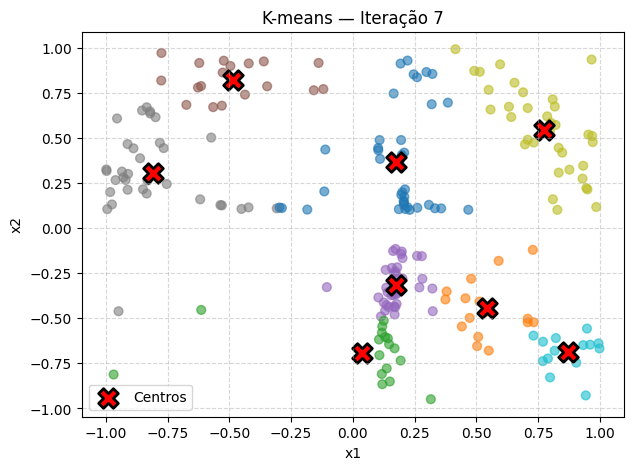

K-means convergiu na iteração 7!
Matriz de confusão — Treino:
        Prev 0  Prev 1
Real 0      97       8
Real 1      12      93 

Matriz de confusão — Teste:
        Prev 0  Prev 1
Real 0      42       3
Real 1       8      37 



,Acurácia,Precisão,Recall,F1
Conjunto,,,,
Treino,0.9048,0.9208,0.8857,0.9029
Teste,0.8778,0.9250,0.8222,0.8706


In [ ]:
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score, f1_score)

model = train_rbf(X_train, y_train, k=8, sigma=0.35, seed=42)
X_test = df_test[['x1', 'x2']].values
y_test = df_test['classe'].values

pred_train = predict_rbf(X_train, model)[0]
pred_test  = predict_rbf(X_test,  model)[0]

# Matrizes de confusão (linhas = real, colunas = previsto)
for nome, yt, yp in [('Treino', y_train, pred_train), ('Teste', y_test, pred_test)]:
    print(f'Matriz de confusão — {nome}:')
    print(pd.DataFrame(confusion_matrix(yt, yp),
                       index=['Real 0', 'Real 1'],
                       columns=['Prev 0', 'Prev 1']), '\n')

def linha_metricas(y_true, y_pred):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, zero_division=0),
            recall_score(y_true, y_pred, zero_division=0),
            f1_score(y_true, y_pred, zero_division=0)]

tabela = pd.DataFrame(
    [linha_metricas(y_train, pred_train), linha_metricas(y_test, pred_test)],
    index=['Treino', 'Teste'],
    columns=['Acurácia', 'Precisão', 'Recall', 'F1']
).round(4)
tabela.index.name = 'Conjunto'
tabela

# Parte G - Fronteira de decisão

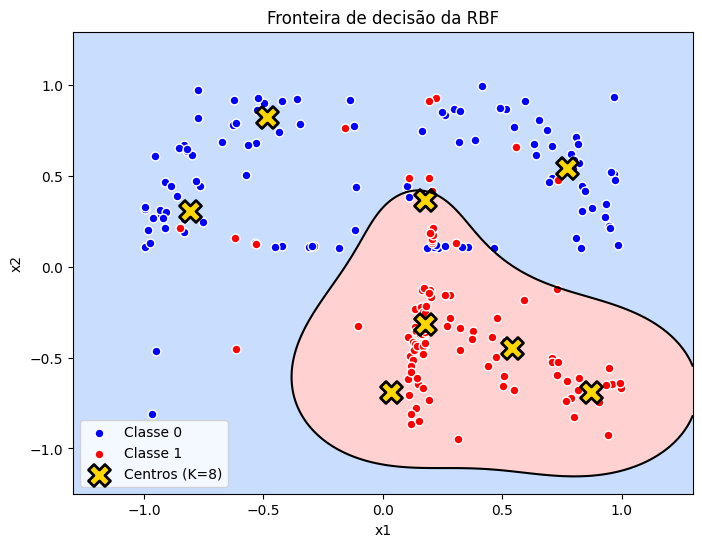

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

margem = 0.3
x_min, x_max = X_train[:, 0].min() - margem, X_train[:, 0].max() + margem
y_min, y_max = X_train[:, 1].min() - margem, X_train[:, 1].max() + margem
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))
grade = np.c_[xx.ravel(), yy.ravel()]

# ativações RBF + 2) bias
Phi_grade = rbf_features(grade, model['centers'], model['sigma'])
# saída da rede
y_grade = Phi_grade @ model['w']
# classe
classe_grade = (y_grade >= 0).astype(int).reshape(xx.shape)

cmap_fundo = ListedColormap(['#a6c8ff', '#ffb3b3'])

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, classe_grade, levels=[-0.5, 0.5, 1.5], cmap=cmap_fundo, alpha=0.6)
plt.contour(xx, yy, y_grade.reshape(xx.shape), levels=[0], colors='k', linewidths=1.5)

for c, cor, nome in [(0, 'blue', 'Classe 0'), (1, 'red', 'Classe 1')]:
    d = df_train[df_train['classe'] == c]
    plt.scatter(d['x1'], d['x2'], color=cor, edgecolors='white', s=40, label=nome)

plt.scatter(model['centers'][:, 0], model['centers'][:, 1], c='gold', marker='X',
            s=250, edgecolors='black', linewidths=2, label='Centros (K=8)')

plt.title('Fronteira de decisão da RBF')
plt.xlabel('x1'); plt.ylabel('x2')
plt.legend()
plt.show()

### Pergunta: Explique por que uma camada de saída linear consegue produzir uma fronteira não linear no espaço original.

Uma camada de saída linear consegue produzir uma fronteira não linear porque a linearidade se refere às ativações e não às coordenadas originais

# Parte H - Estudo do parâmetro σ

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

X_train = df_train[['x1', 'x2']].values
y_train = df_train['classe'].values
X_test  = df_test[['x1', 'x2']].values
y_test  = df_test['classe'].values

def avaliar(k, sigma, seed=42):
    model = train_rbf(X_train, y_train, k=k, sigma=sigma, seed=seed)
    p_tr = predict_rbf(X_train, model)[0]
    p_te = predict_rbf(X_test,  model)[0]
    return (accuracy_score(y_train, p_tr),
            accuracy_score(y_test,  p_te),
            f1_score(y_test, p_te, zero_division=0))

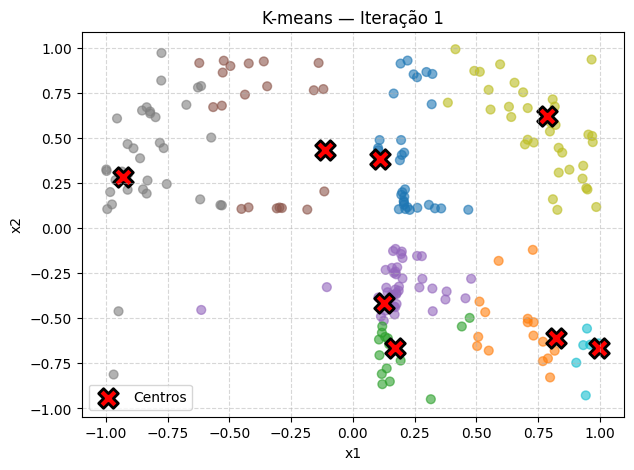

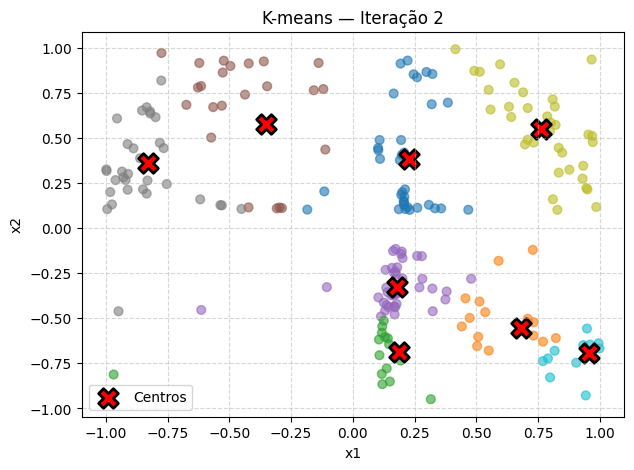

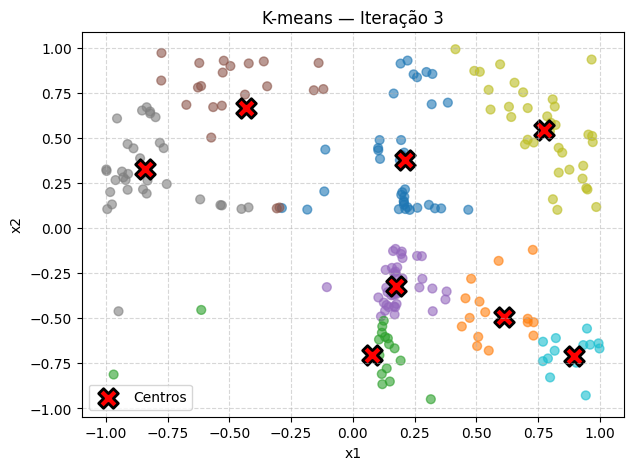

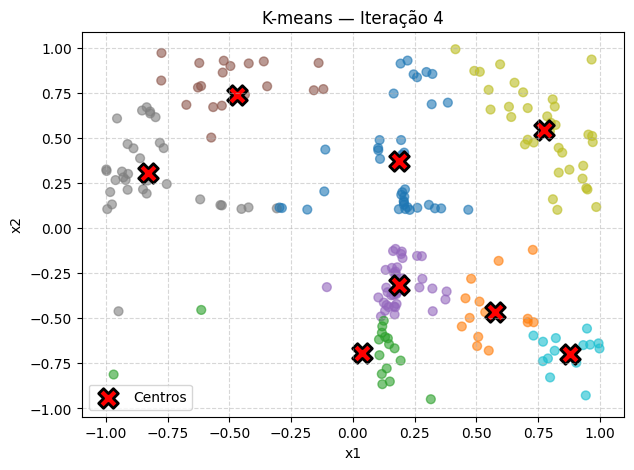

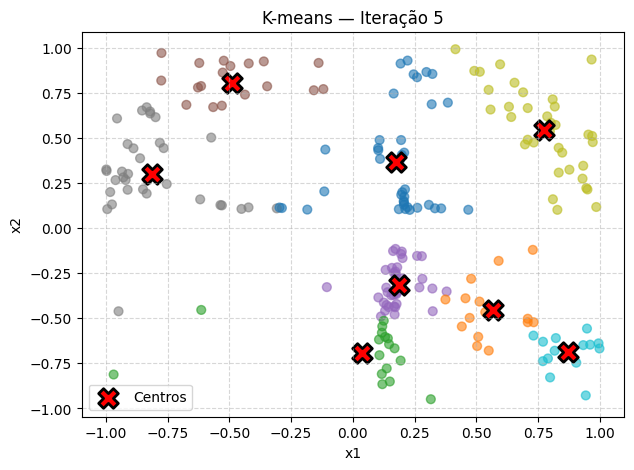

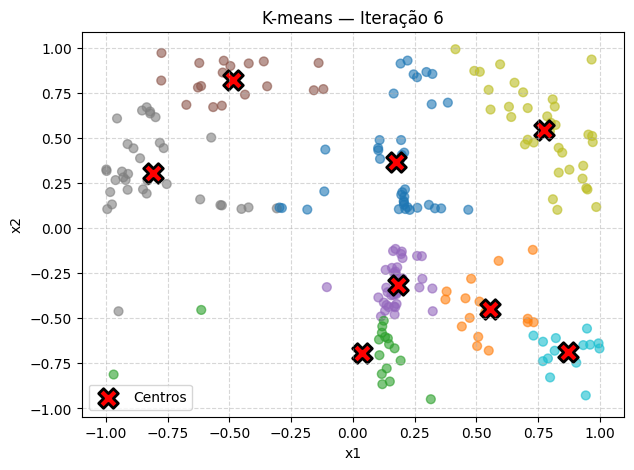

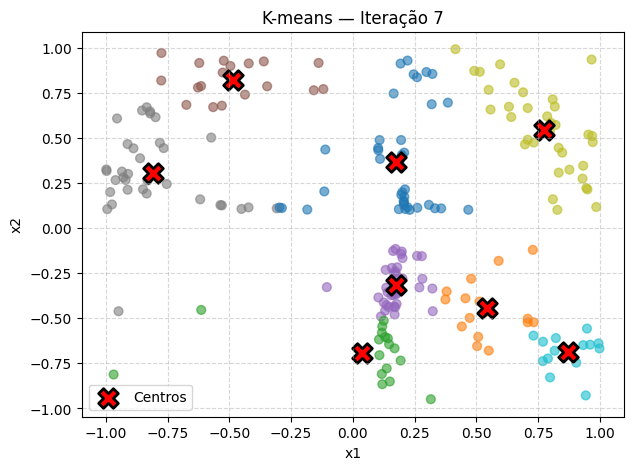

K-means convergiu na iteração 7!


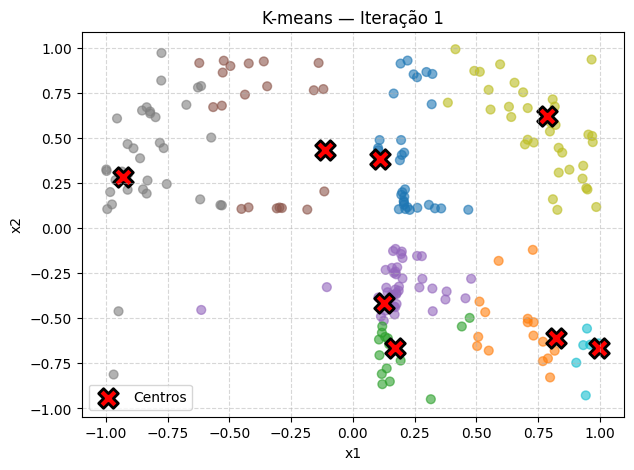

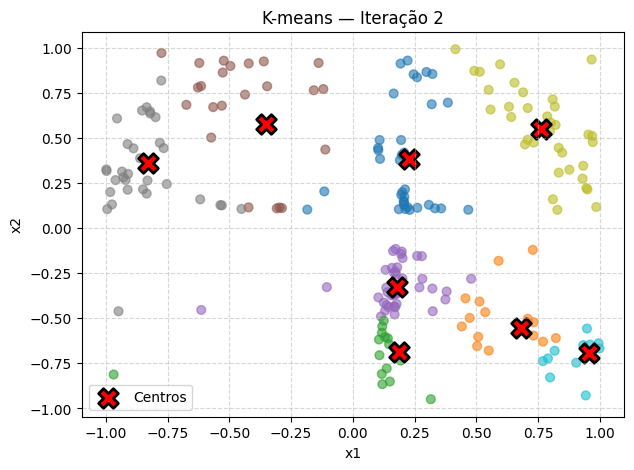

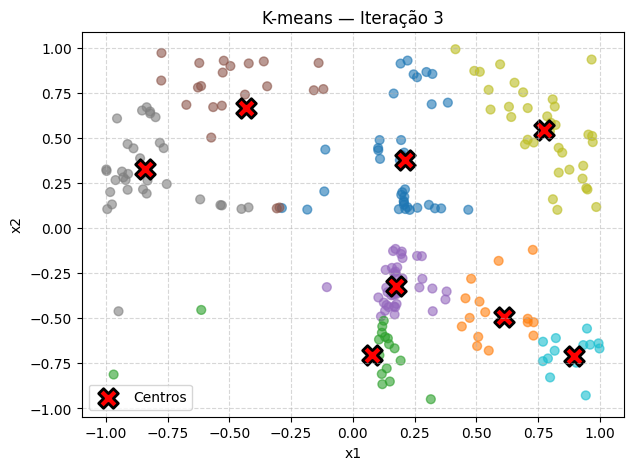

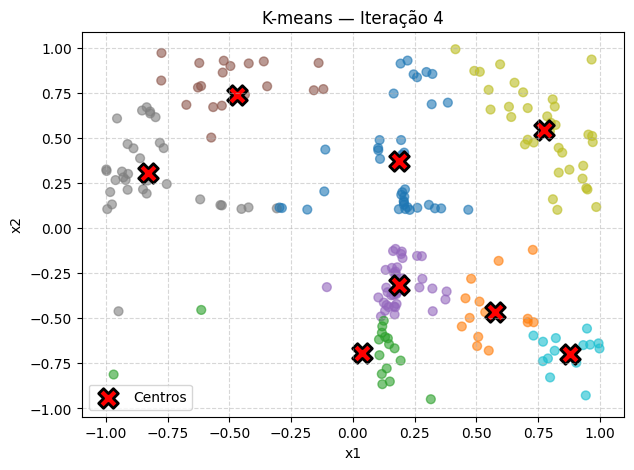

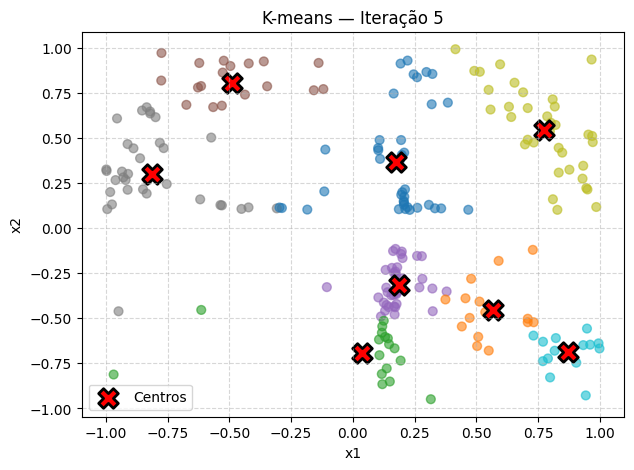

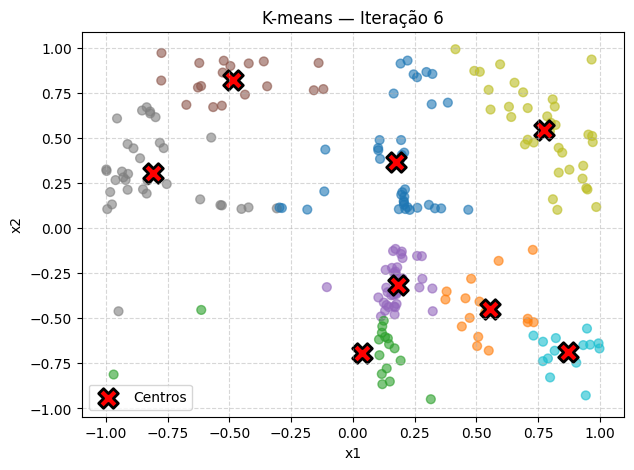

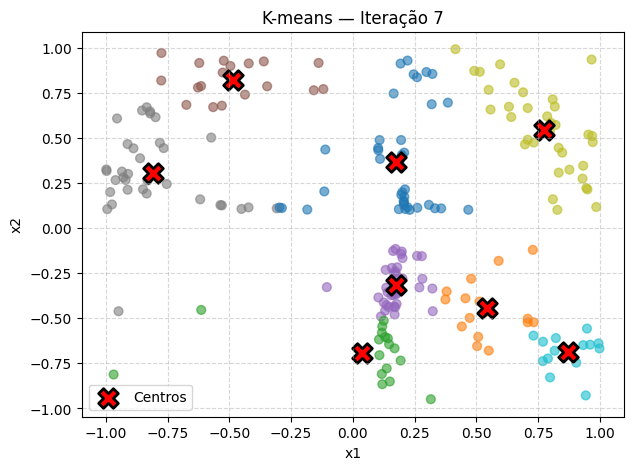

K-means convergiu na iteração 7!


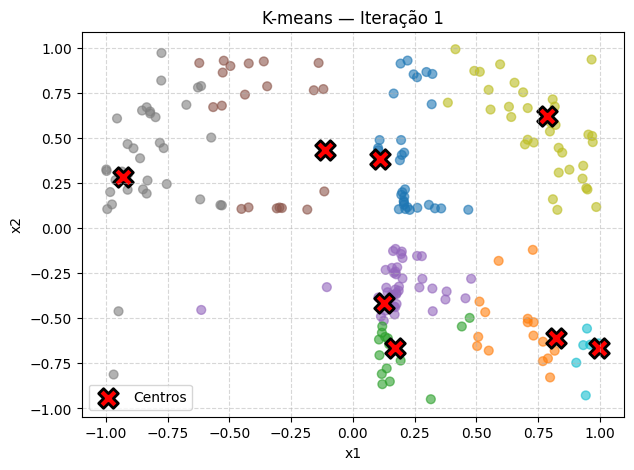

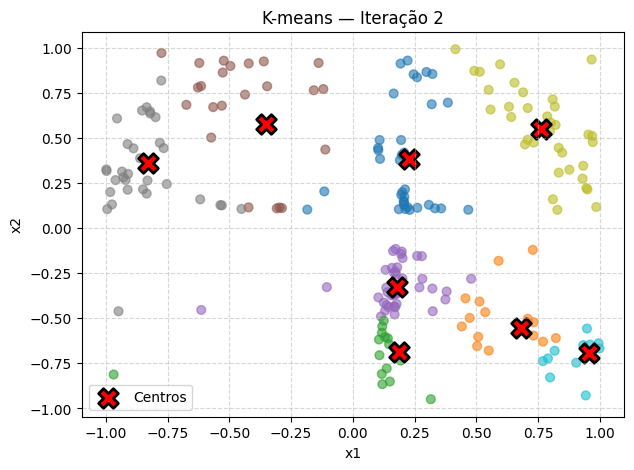

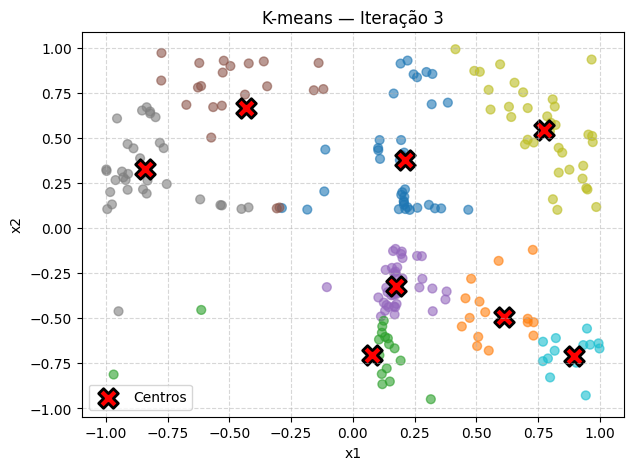

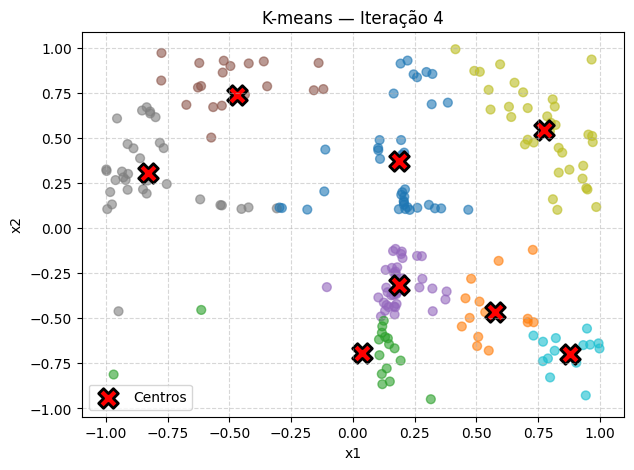

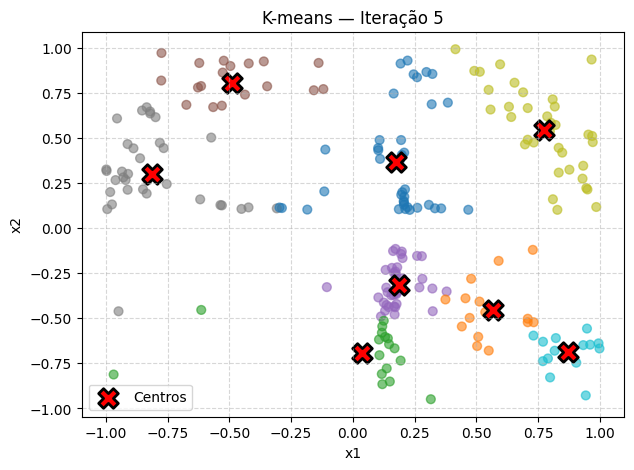

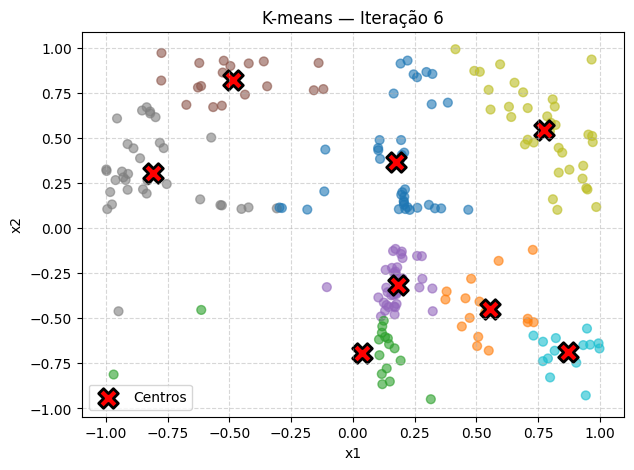

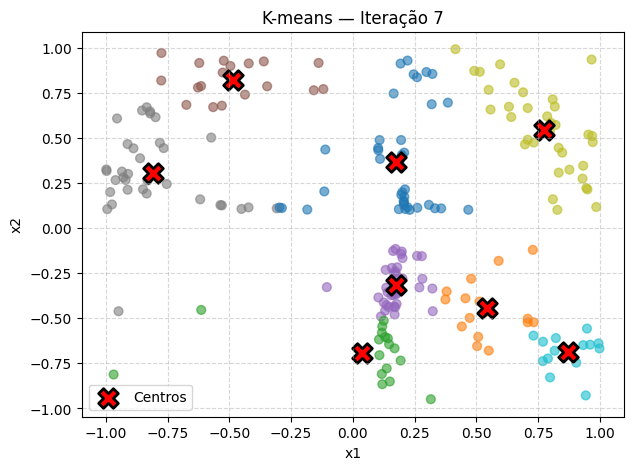

K-means convergiu na iteração 7!


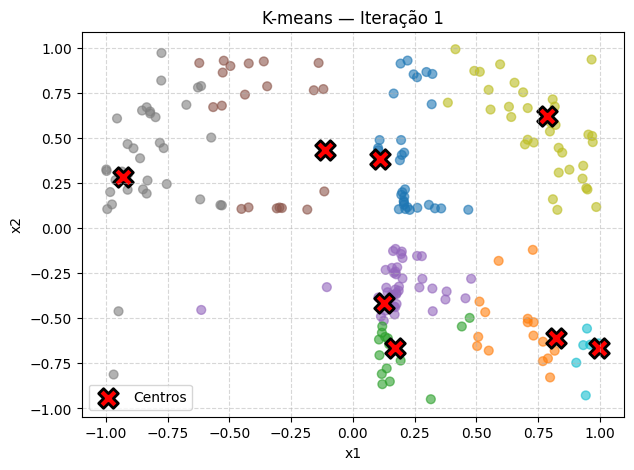

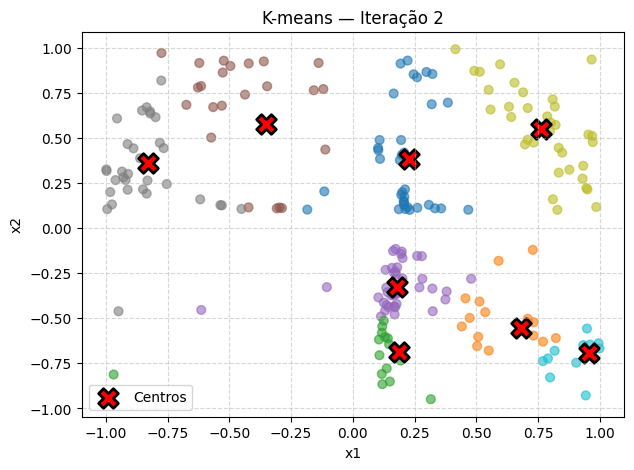

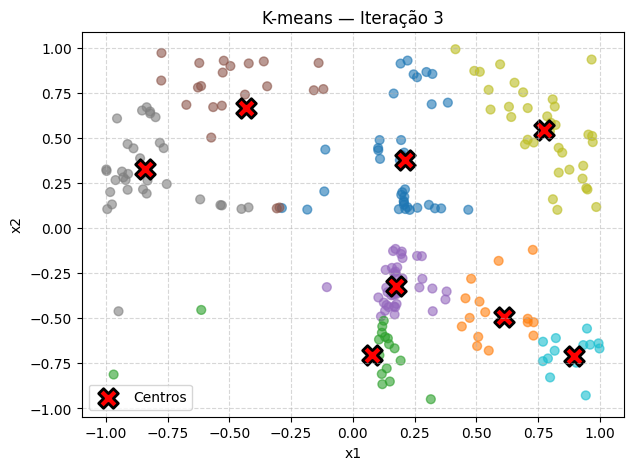

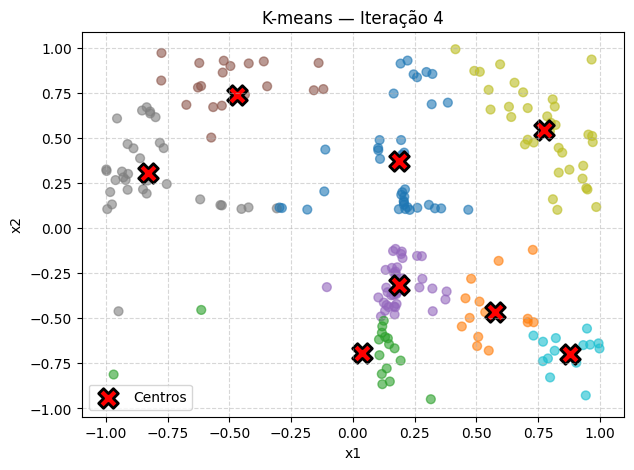

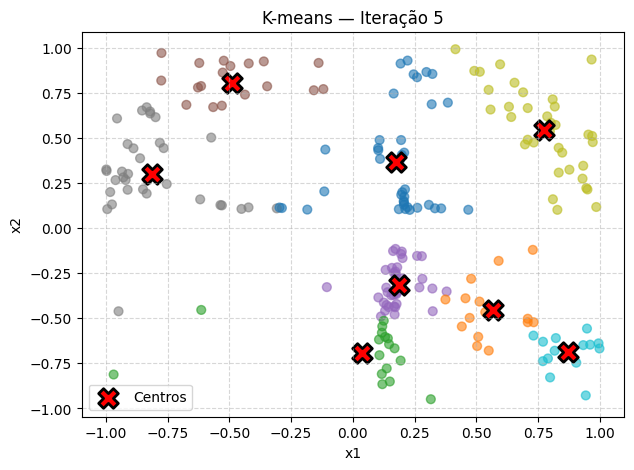

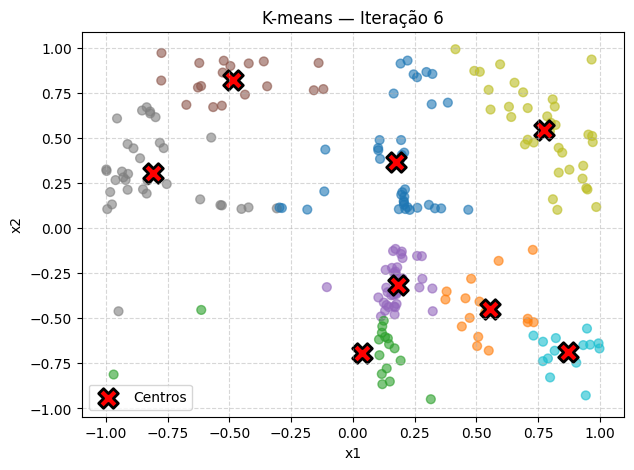

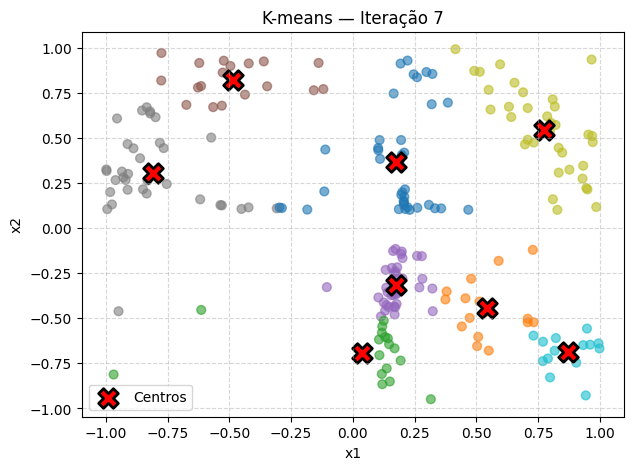

K-means convergiu na iteração 7!


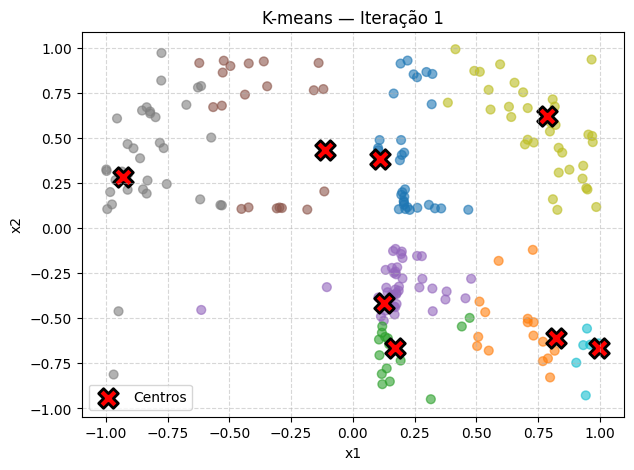

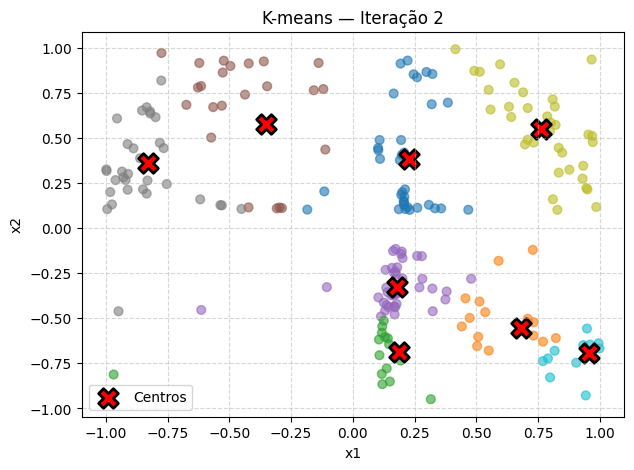

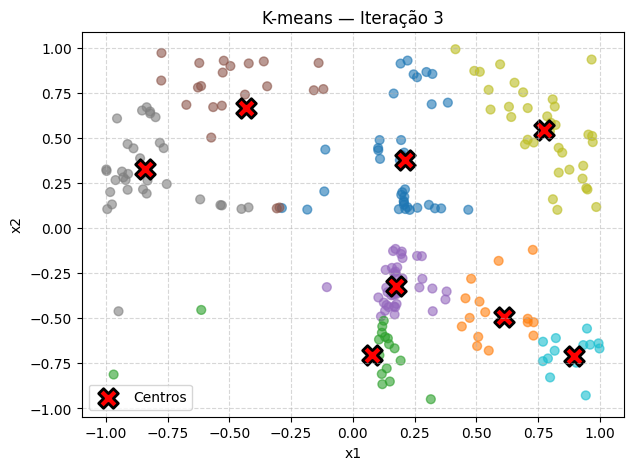

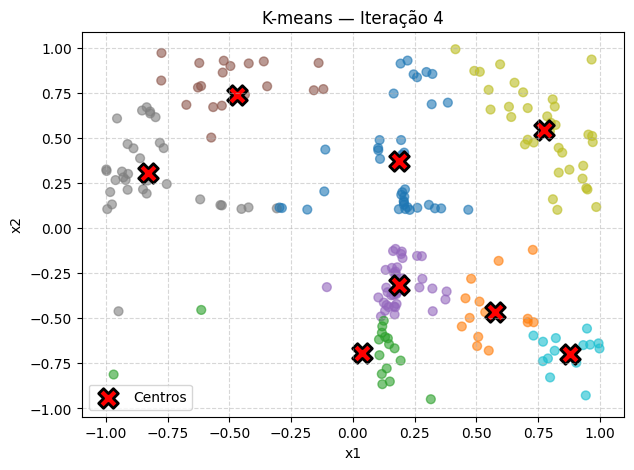

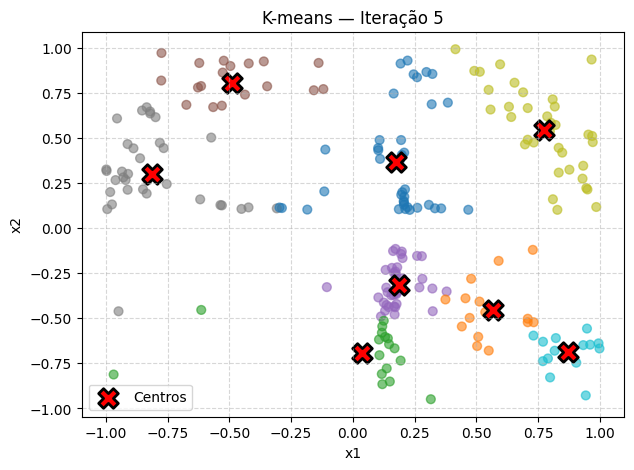

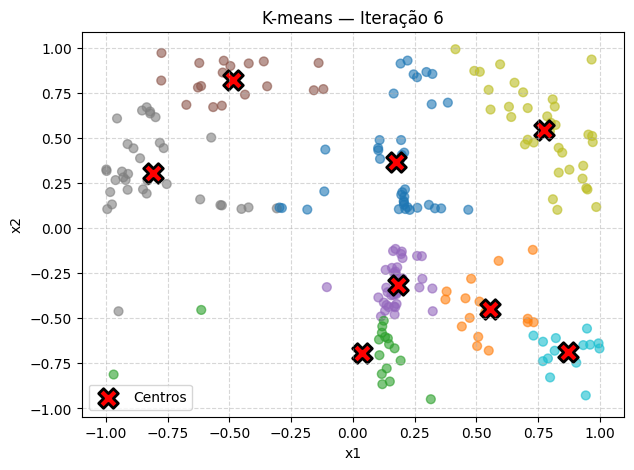

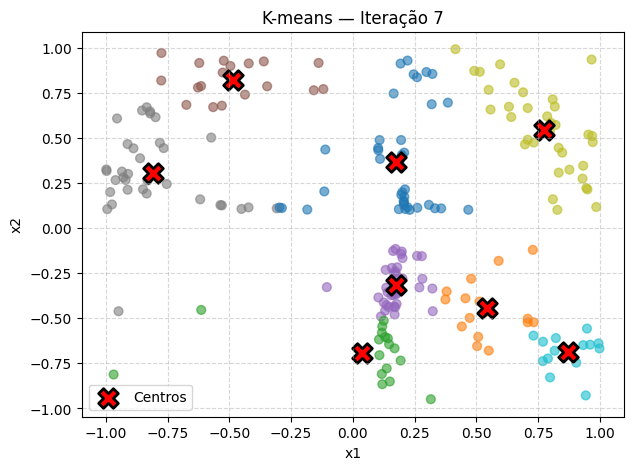

K-means convergiu na iteração 7!


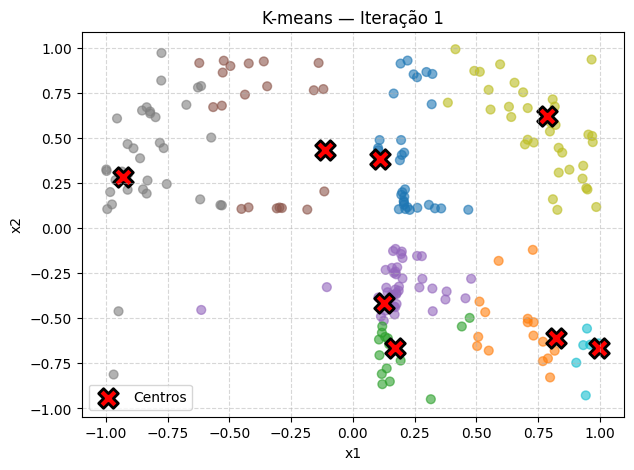

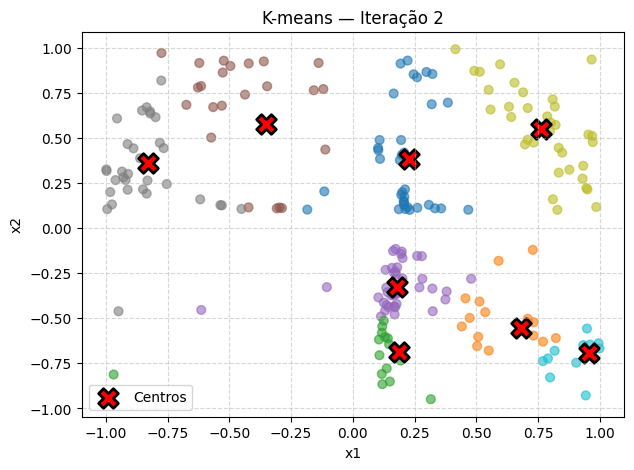

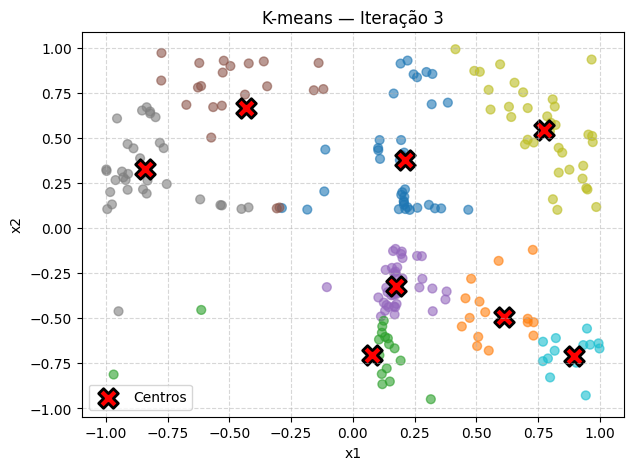

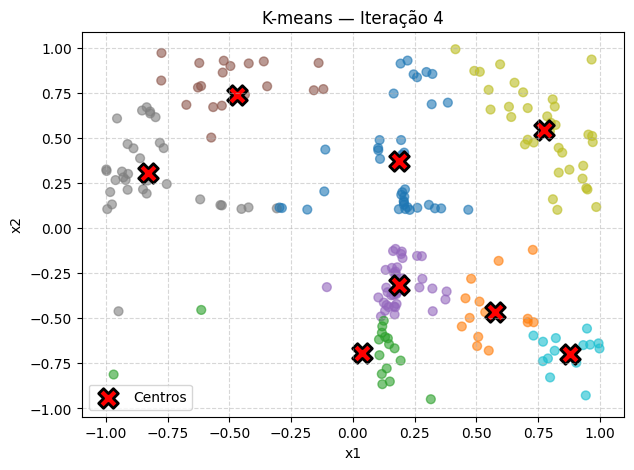

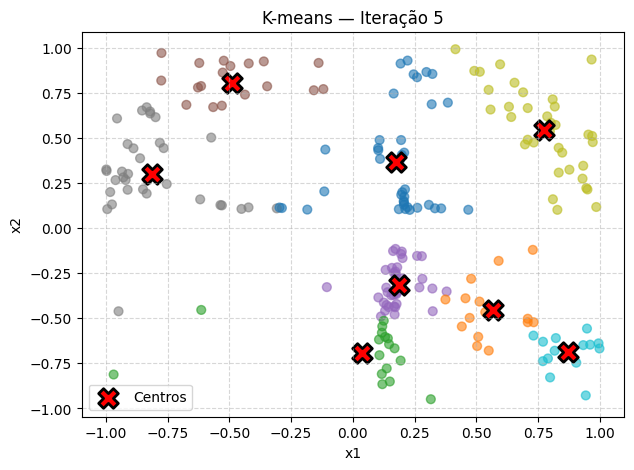

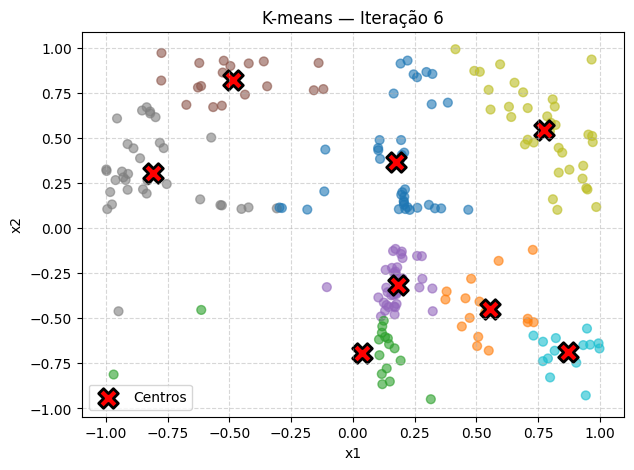

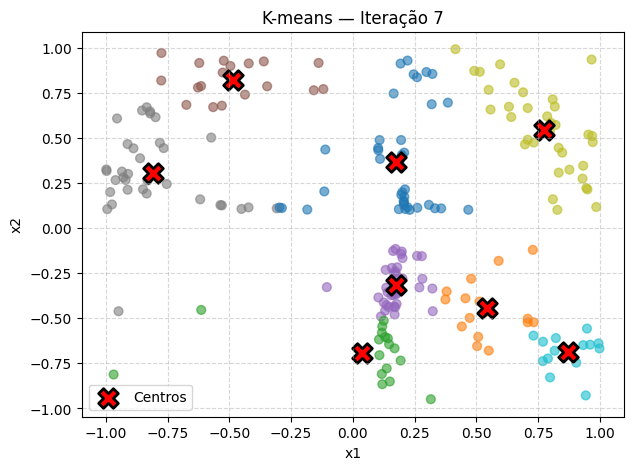

K-means convergiu na iteração 7!


,σ,Acurácia treino,Acurácia teste,F1 teste
0,0.10,0.8524,0.8333,0.8000
1,0.20,0.9190,0.8778,0.8675
2,0.35,0.9048,0.8778,0.8706
3,0.50,0.8857,0.8778,0.8736
4,0.80,0.8857,0.8667,0.8636
5,1.20,0.8905,0.8667,0.8636


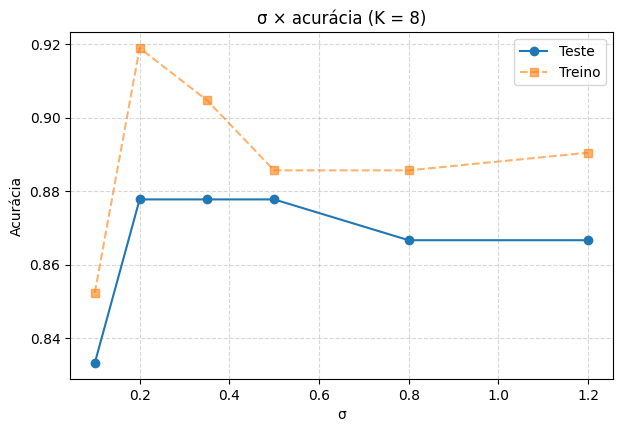

In [ ]:
sigmas = [0.10, 0.20, 0.35, 0.50, 0.80, 1.20]

res_sigma = pd.DataFrame(
    [(s, *avaliar(k=8, sigma=s)) for s in sigmas],
    columns=['σ', 'Acurácia treino', 'Acurácia teste', 'F1 teste']
).round(4)
display(res_sigma)

plt.figure(figsize=(7, 4.5))
plt.plot(res_sigma['σ'], res_sigma['Acurácia teste'], 'o-', label='Teste')
plt.plot(res_sigma['σ'], res_sigma['Acurácia treino'], 's--', alpha=0.6, label='Treino')
plt.xlabel('σ'); plt.ylabel('Acurácia')
plt.title('σ × acurácia (K = 8)')
plt.grid(True, linestyle='--', alpha=0.5); plt.legend()
plt.show()

### Perguntas
1. Qual σ apresentou o melhor resultado? -> R=  {0.50}. Esse valor de parâmetro alcançou desempenho mais equilibrado com menor diferença percentual entre treino e teste
2. O menor σ foi necessariamente o melhor? -> R = Não, esse valor de parâmetro obteve o pior desempenho dentre todas as métricas
3. O maior σ foi necessariamente o melhor? -> R = Não, esse valor ficou abaixo do melhor.
4. Existe evidência de underfitting ou overfitting? -> R = Underfitting em σ = 0,10. Há uma tendência de overfitting em σ = 0,20. Também há uma tendência de overfitting para os maiores valores de σ (0,80 e 1,20)

# Parte I - Estudo do número de centros

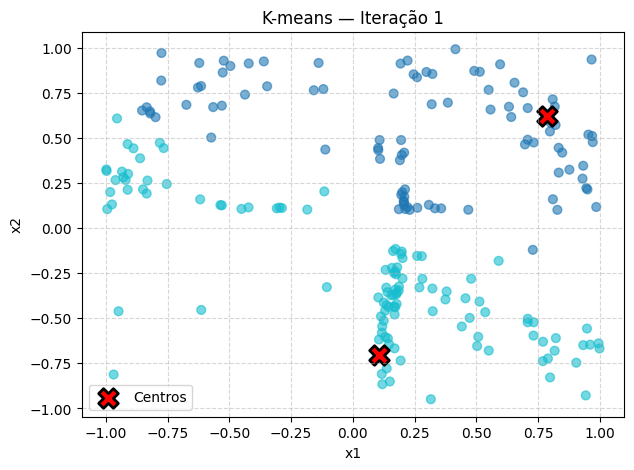

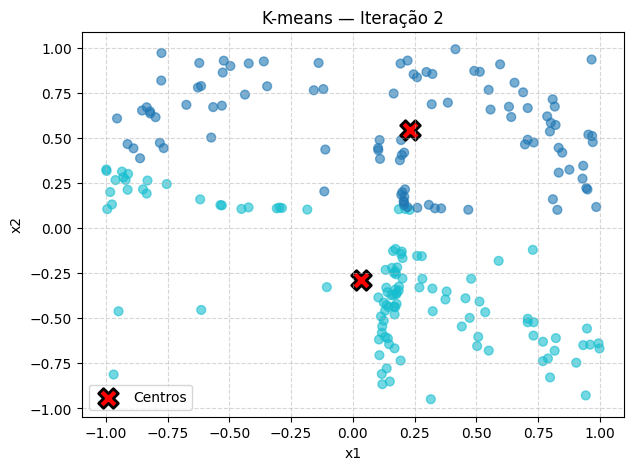

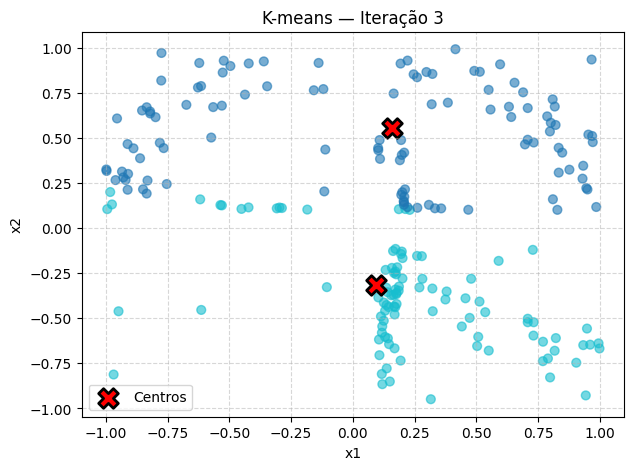

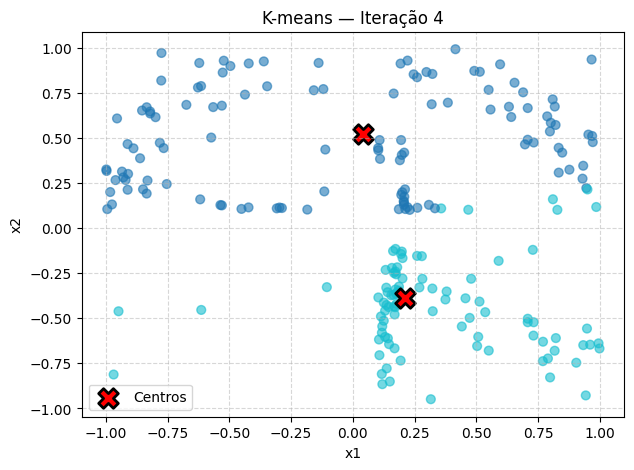

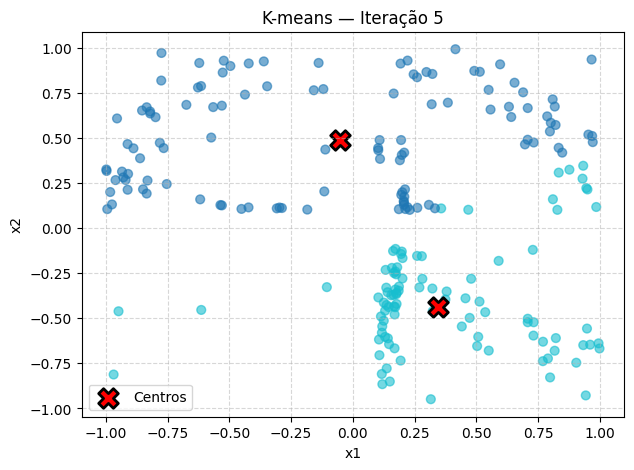

...

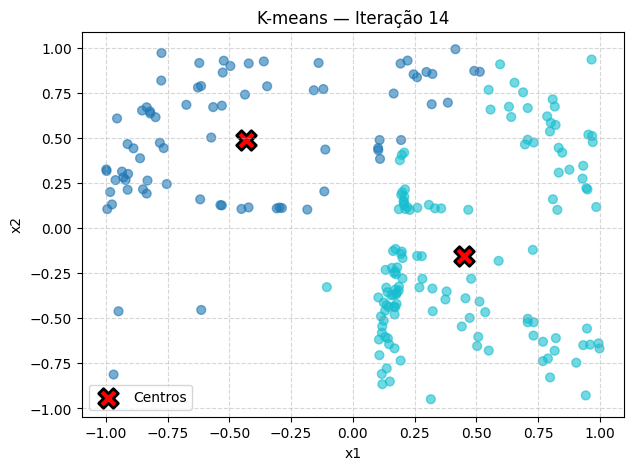

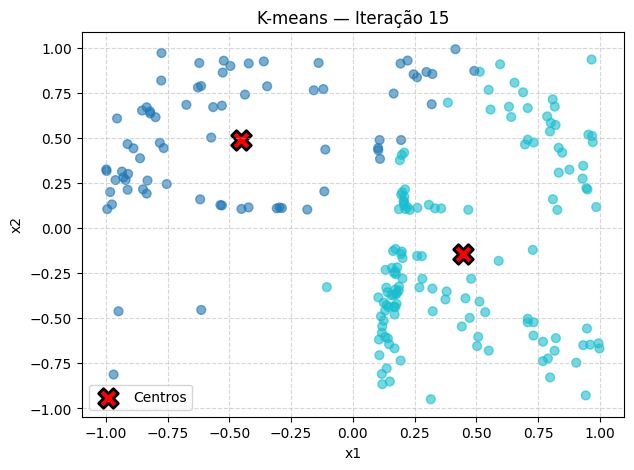

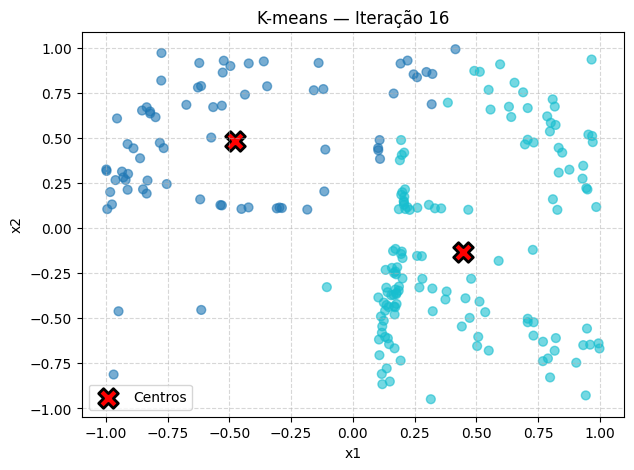

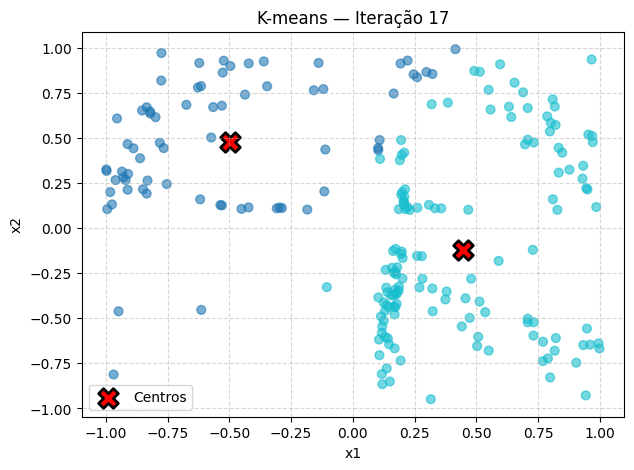

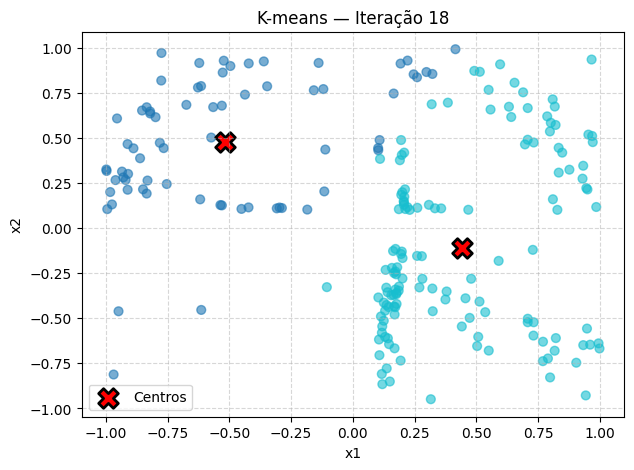

K-means convergiu na iteração 18!


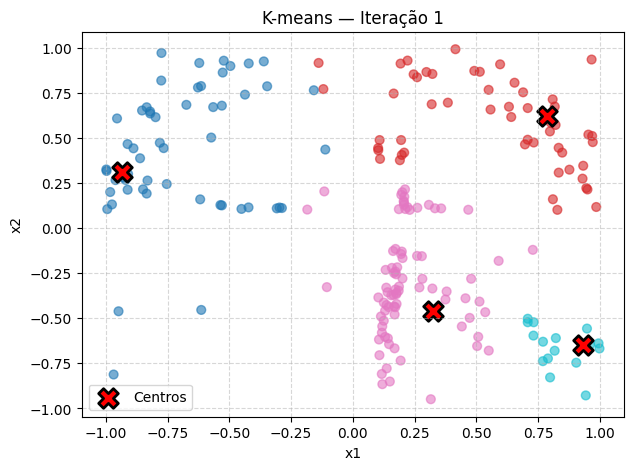

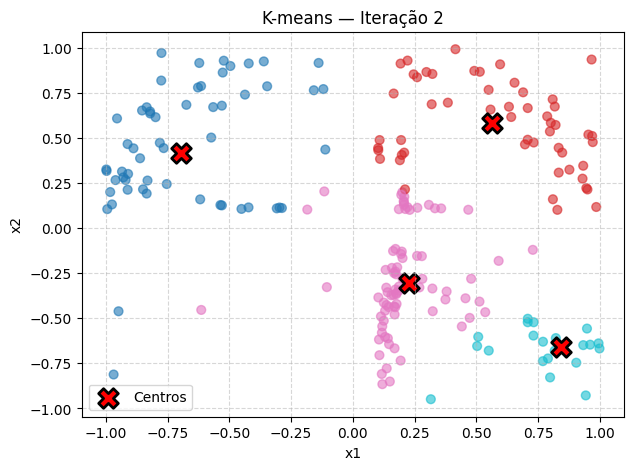

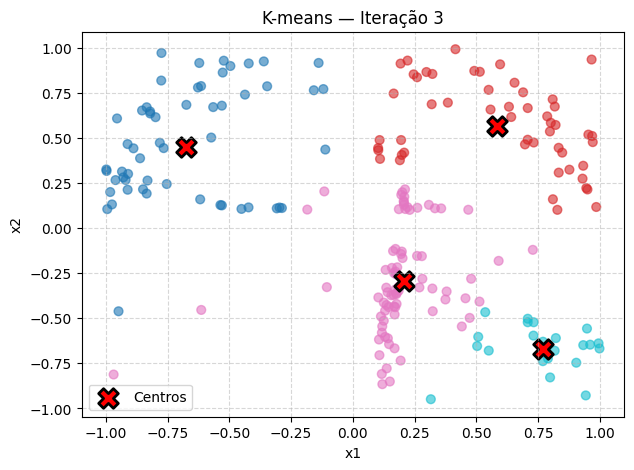

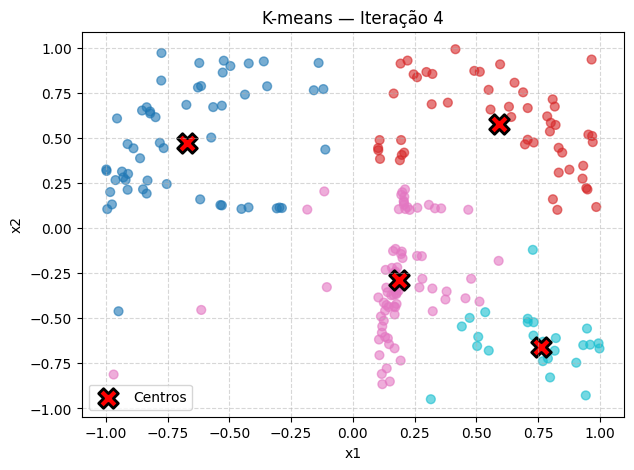

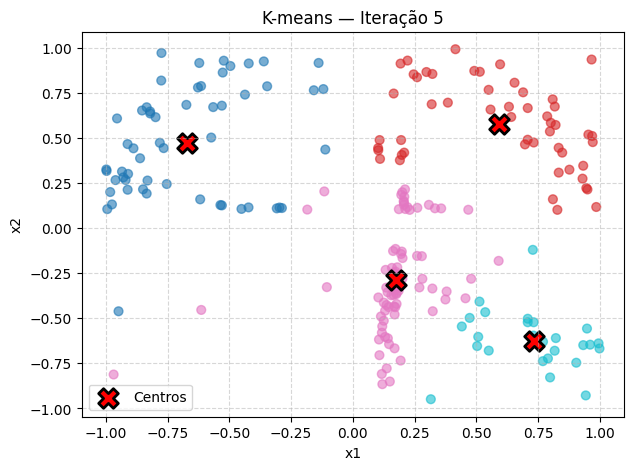

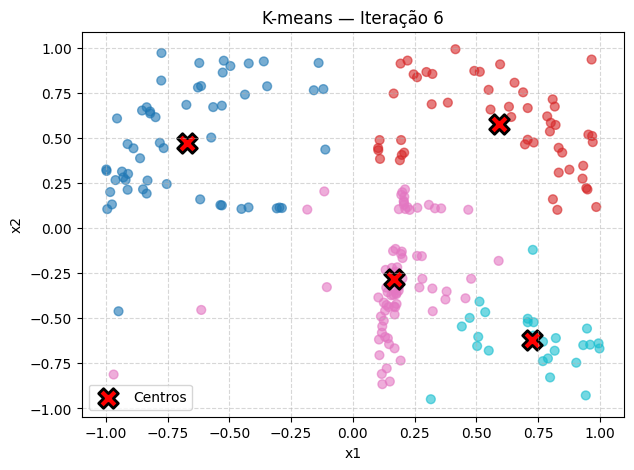

K-means convergiu na iteração 6!


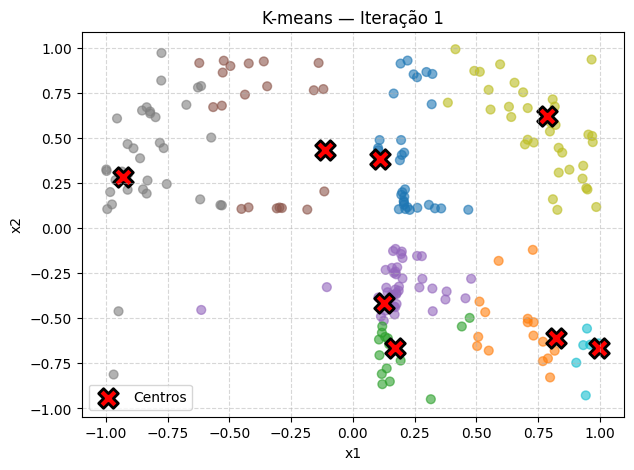

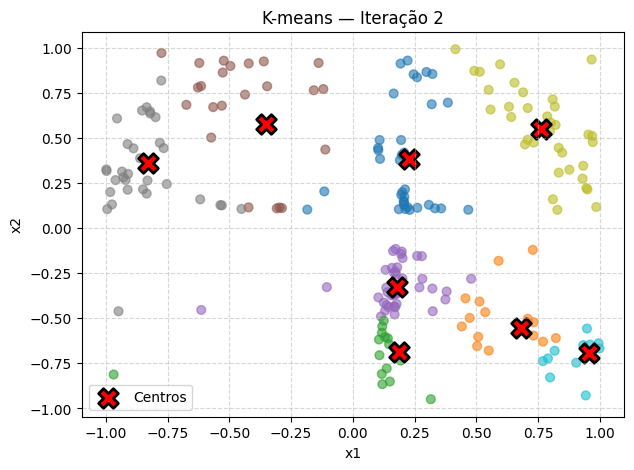

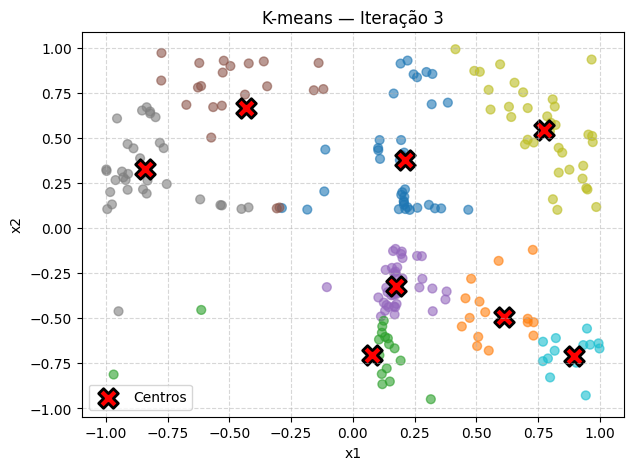

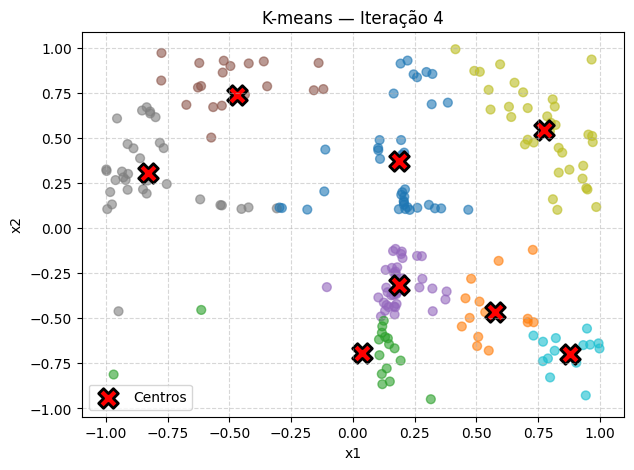

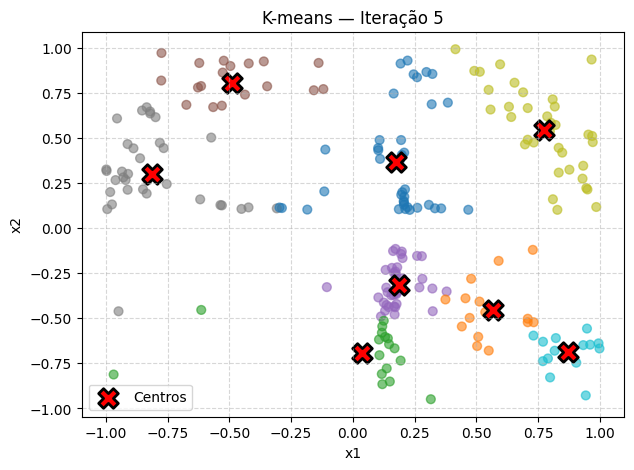

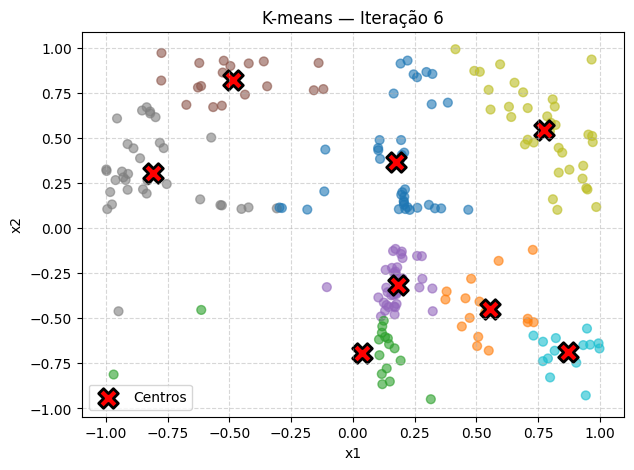

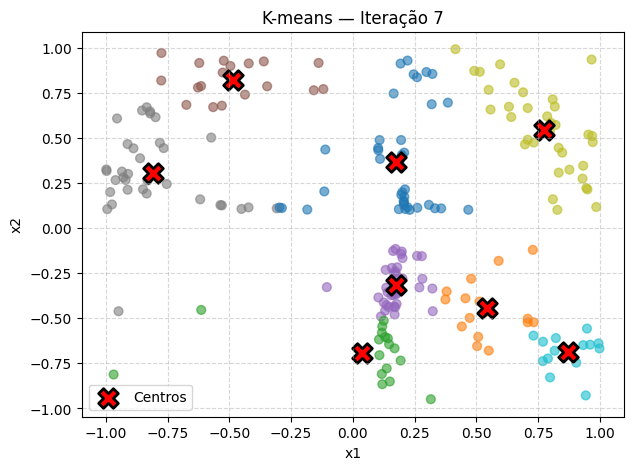

K-means convergiu na iteração 7!


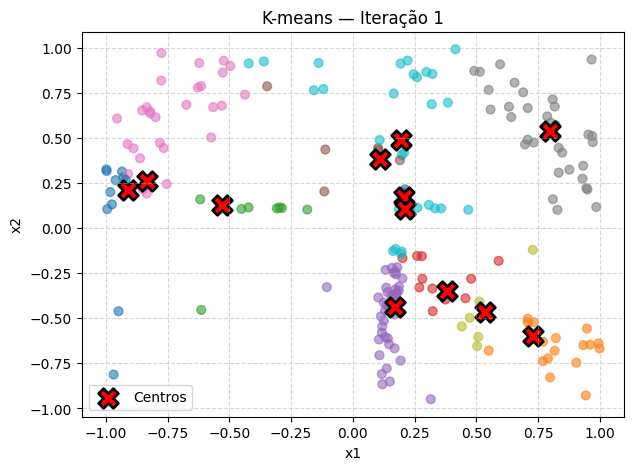

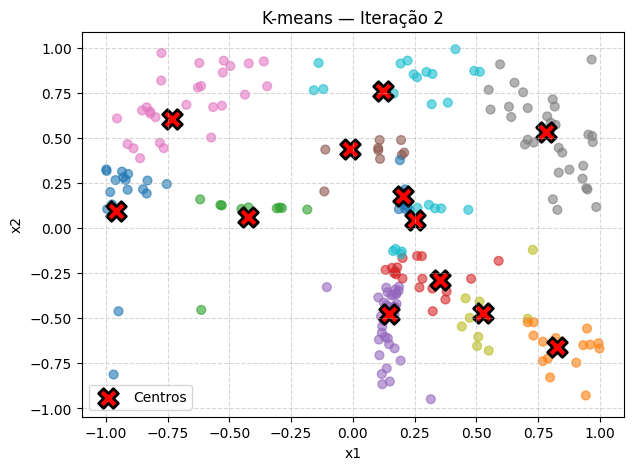

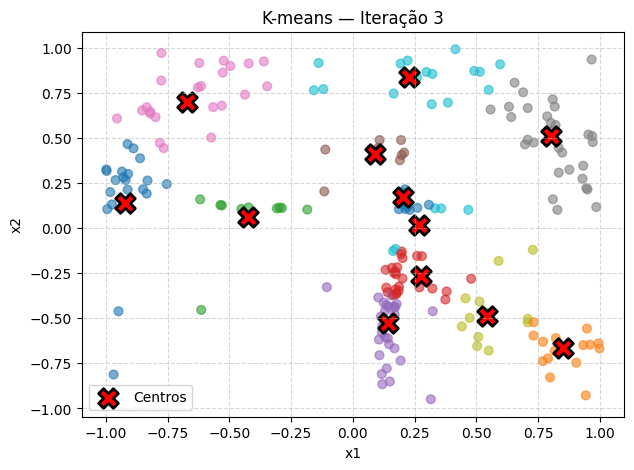

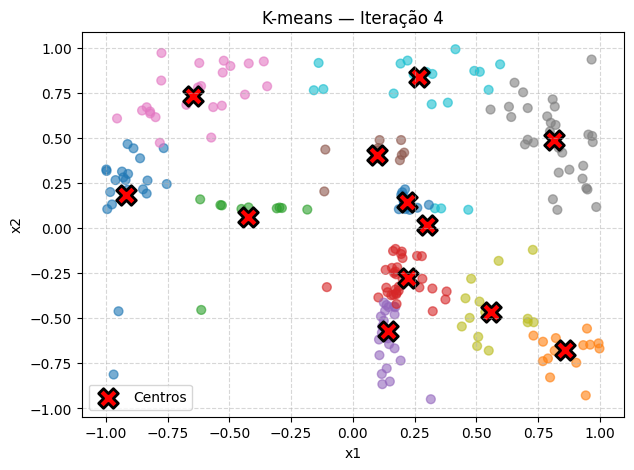

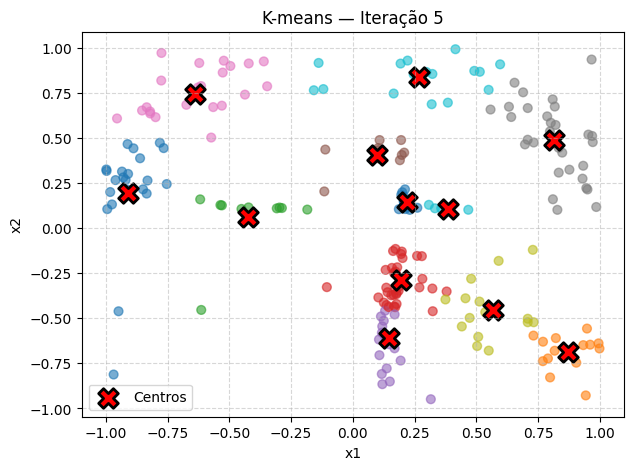

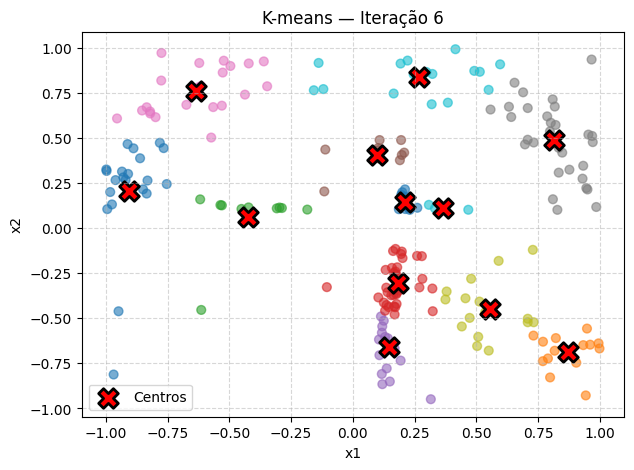

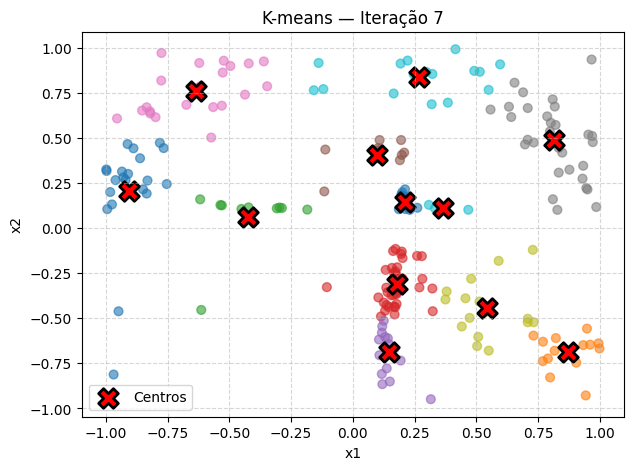

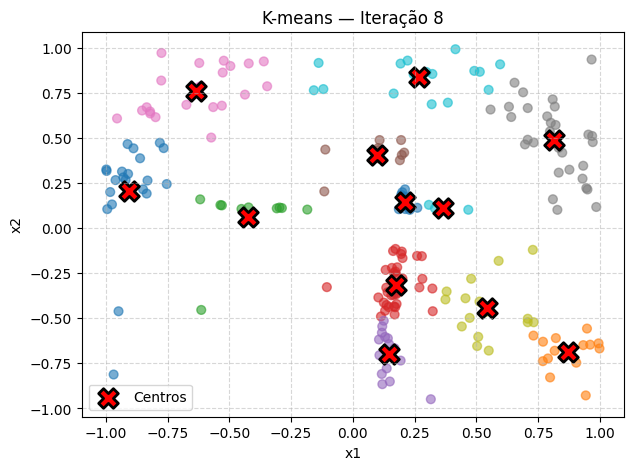

K-means convergiu na iteração 8!


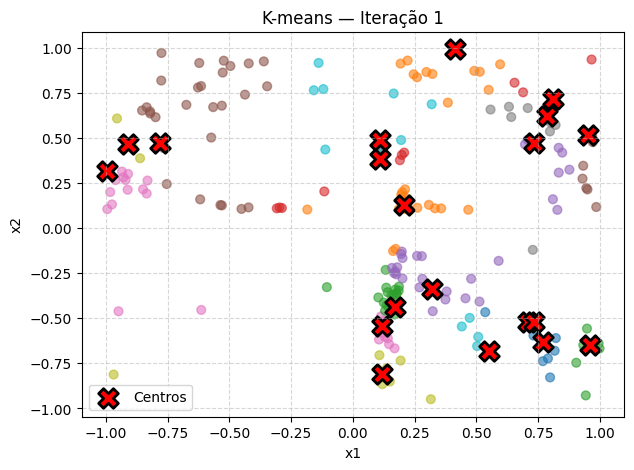

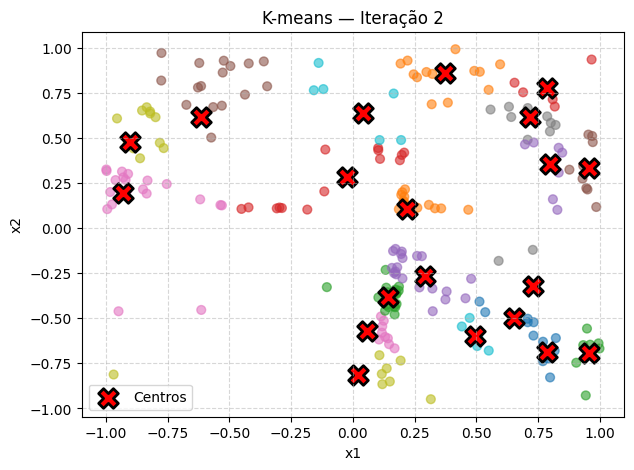

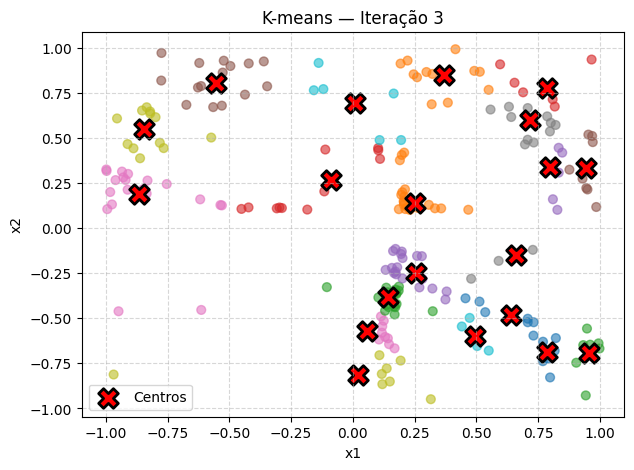

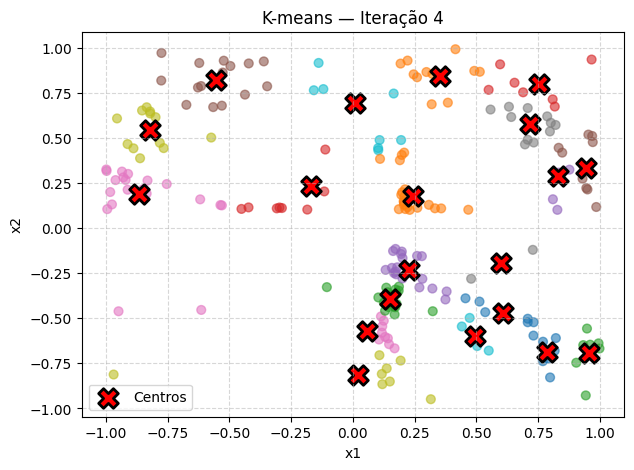

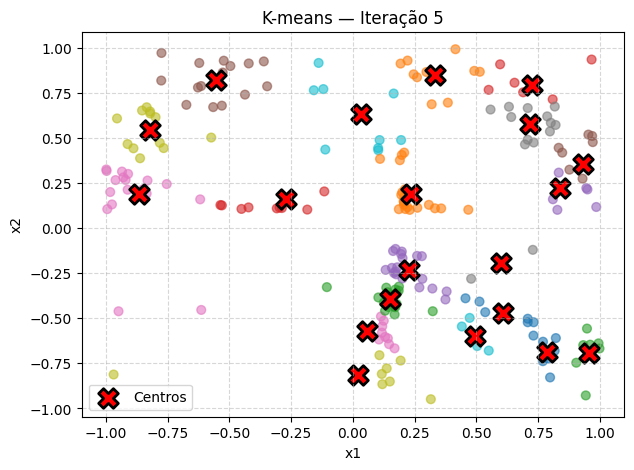

...

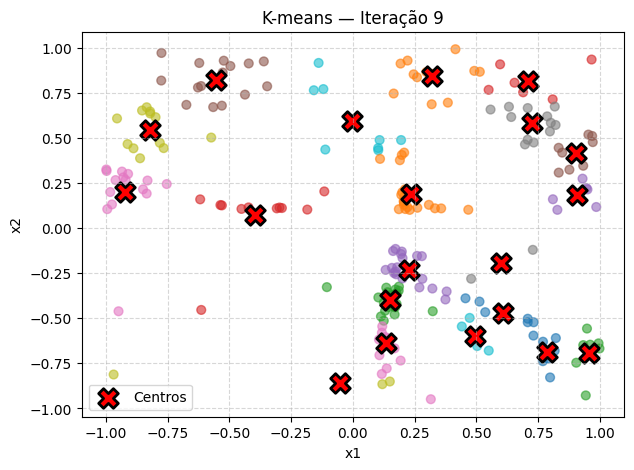

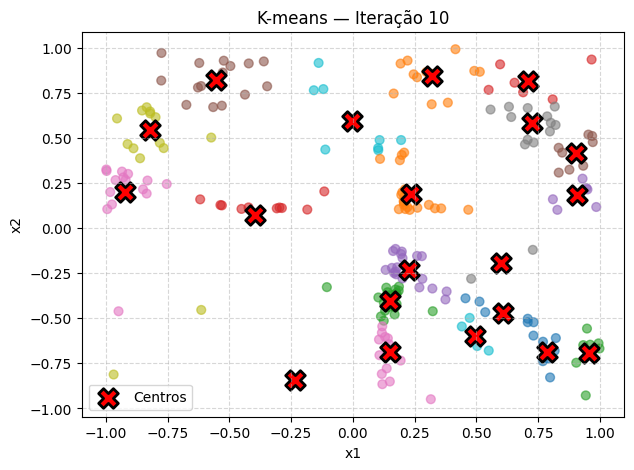

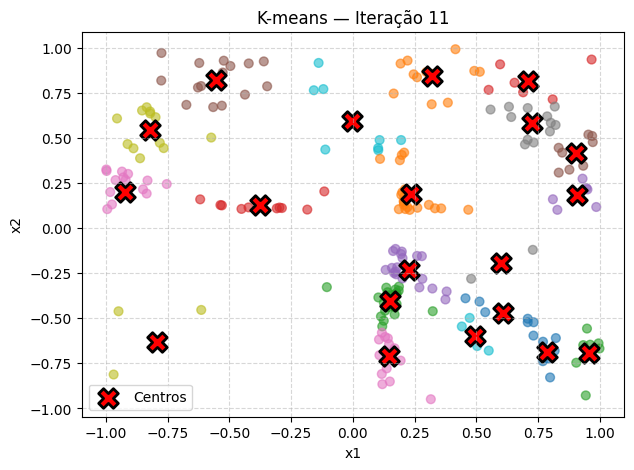

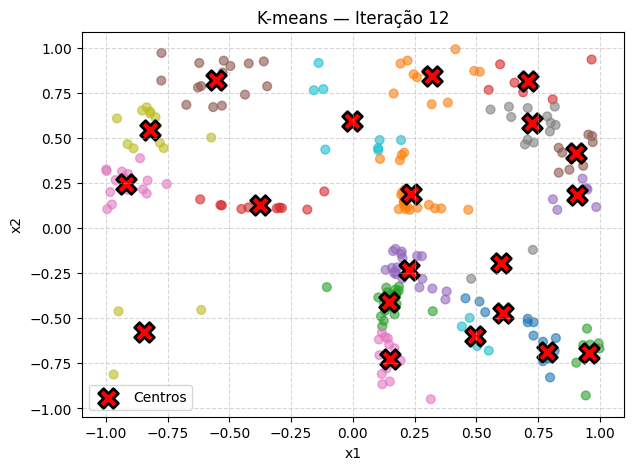

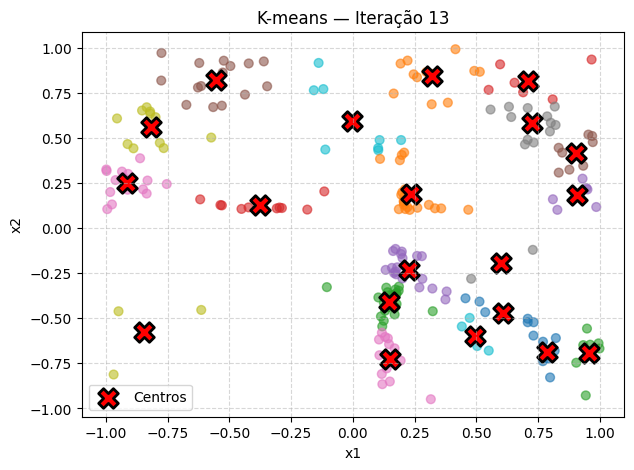

K-means convergiu na iteração 13!


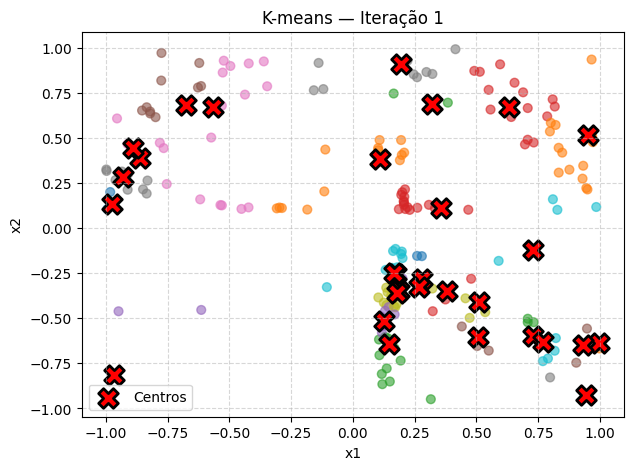

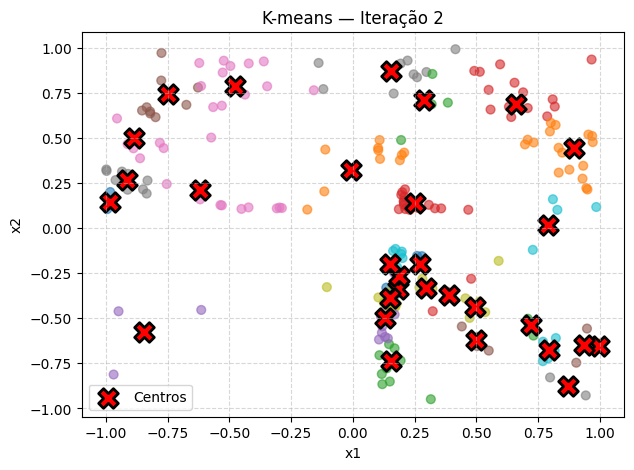

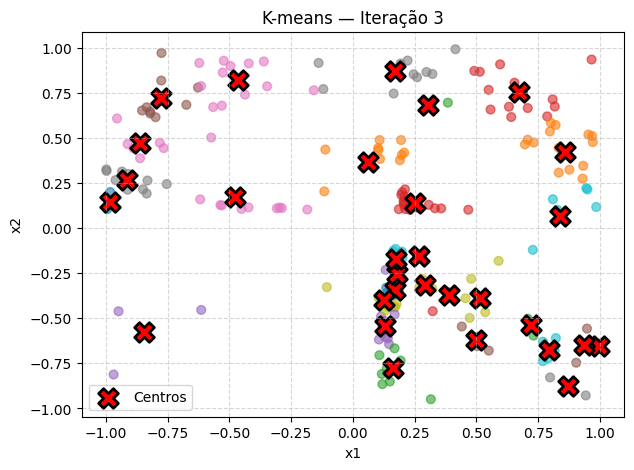

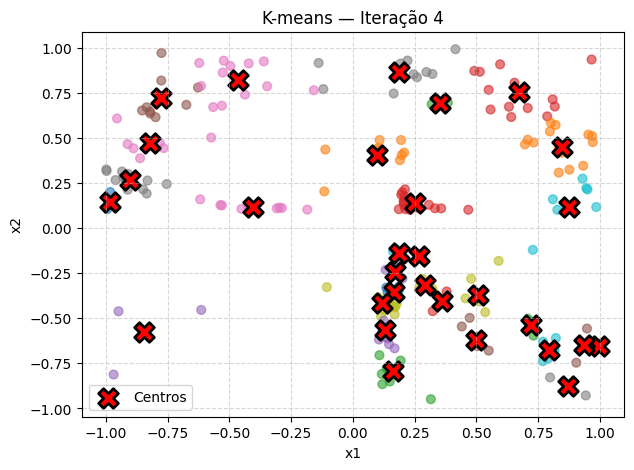

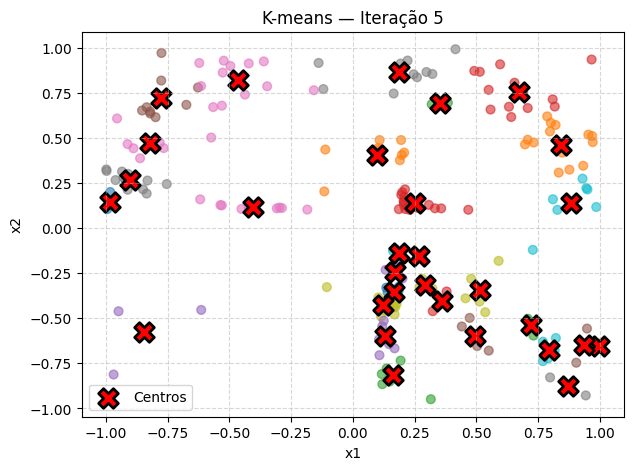

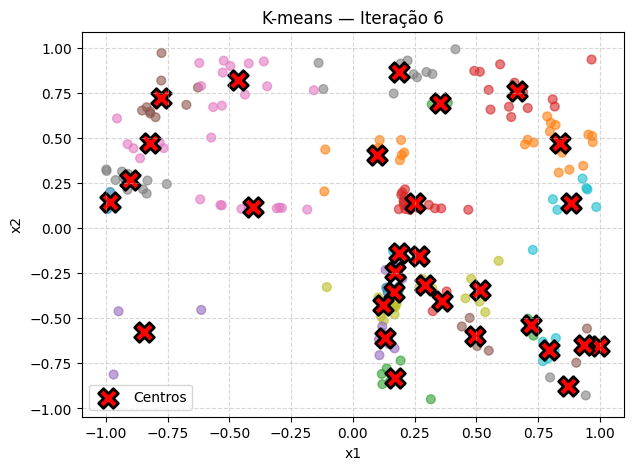

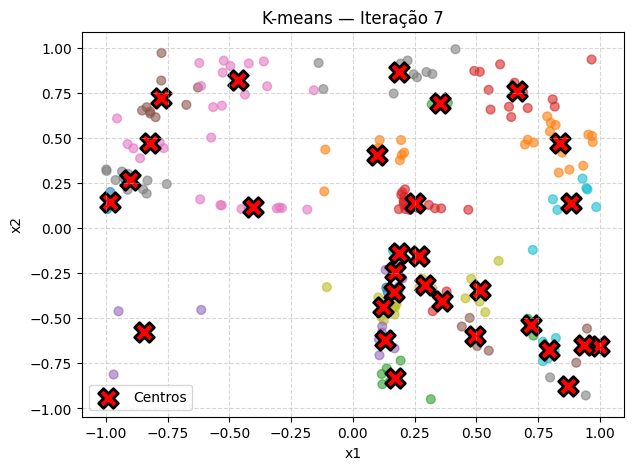

K-means convergiu na iteração 7!


,K,Acurácia treino,Acurácia teste,F1 teste
0,2,0.7952,0.8111,0.8046
1,4,0.8810,0.8667,0.8571
2,8,0.9048,0.8778,0.8706
3,12,0.8952,0.8667,0.8605
4,20,0.8952,0.8778,0.8706
5,30,0.9381,0.8667,0.8537


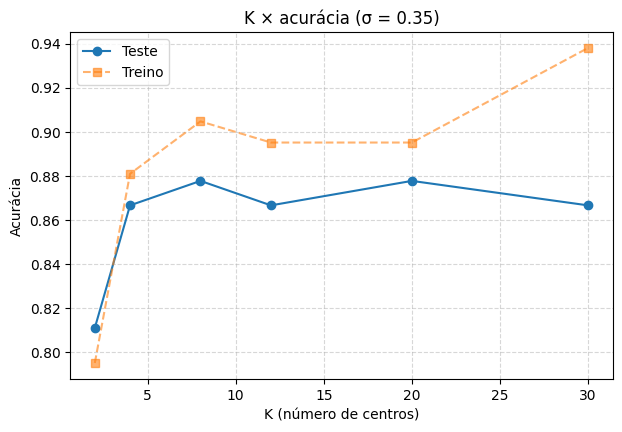

In [ ]:
ks = [2, 4, 8, 12, 20, 30]

res_k = pd.DataFrame(
    [(k, *avaliar(k=k, sigma=0.35)) for k in ks],
    columns=['K', 'Acurácia treino', 'Acurácia teste', 'F1  teste']
).round(4)
display(res_k)

plt.figure(figsize=(7, 4.5))
plt.plot(res_k['K'], res_k['Acurácia teste'], 'o-', label='Teste')
plt.plot(res_k['K'], res_k['Acurácia treino'], 's--', alpha=0.6, label='Treino')
plt.xlabel('K (número de centros)'); plt.ylabel('Acurácia')
plt.title('K × acurácia (σ = 0.35)')
plt.grid(True, linestyle='--', alpha=0.5); plt.legend()
plt.show()

### Perguntas
1. Aumentar o número de centros sempre melhora a generalização? -> R = Não. Nesse caso, o ganho grande acontece só de K = 2 para K = 4. A partir daí há uma certa estagnação, conduzindo a uma inferência de que mais centro melhoram o ajuste do modelo aos dados e nem melhoram a generalização.
2. O que acontece com a capacidade da rede quando K aumenta? -> R = A capacidade cresce e a fronteira de decisão pode ficar mais flexível.
3. Qual combinação de K e σ parece oferecer o melhor compromisso? -> R = A melhor configuração seria K=8 com σ variando entre 0,35.

##